In [78]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import os



In [79]:
#import genotype data
genotype = pd.read_csv(
    "../data/raw/Pf8_drug_resistance_marker_genotypes.tsv",
    sep="\t"
)

In [80]:
# viewing data
genotype

,Sample,crt_72[C],crt_74[M],crt_75[N],crt_76[K],crt_72-76[CVMNK],crt_93[T],crt_97[H],crt_218[I],crt_220[A],...,mdr1_1034[S],mdr1_1042[N],mdr1_1226[F],mdr1_1246[D],arps10_127-128[VD],fd_193[D],mdr2_484[T],kelch13_349-726_ns_changes,mdr1_dup_call,pm2_dup_call
0,FP0008-C,C,"I,M","E,N","T,K","CVIET,CVMNK",T,H,I,"S,A",...,S,N,F,D,VD,D,T,NaN,0,0
1,FP0009-C,C,I,E,T,CVIET,T,H,I,S,...,S,N,F,Y,VD,D,T,NaN,0,0
2,FP0010-CW,C,"I,M","E,N","T,K","CVIET,CVMNK",T,H,I,"S,A",...,S,N,F,D,VD,D,T,NaN,0,0
3,FP0011-CW,C,"I,M","E,N","T,K","CVIET,CVMNK",T,H,I,"S,A",...,S,N,F,D,VD,D,T,NaN,0,0
4,FP0012-CW,C,I,E,T,CVIET,T,H,I,S,...,S,N,F,D,VD,D,T,NaN,0,0
5,FP0013-CW,C,I,E,T,CVIET,T,H,I,S,...,S,N,F,D,VD,D,T,NaN,0,0
6,FP0014-CW,C,M,N,K,CVMNK,T,H,I,A,...,S,N,F,D,VD,D,T,NaN,0,0
7,FP0015-C,C,I,E,T,CVIET,T,H,I,S,...,S,N,F,D,VD,D,T,NaN,0,0
8,FP0016-C,C,"I,M","E,N","T,K","CVIET,CVMNK",T,H,I,S,...,S,N,F,D,VD,D,T,NaN,0,0
9,FP0017-C,C,M,N,K,CVMNK,T,H,I,A,...,S,N,F,D,VD,D,T,NaN,0,0


### Data exploration

In [81]:
print(genotype["crt_76[K]"].value_counts(dropna=False))

crt_76[K]
T       12432
K       10768
T,K       607
K,T       550
-          48
T,Q         3
T,Q*        1
Name: count, dtype: int64


In [82]:
# viewing all column count data
genotype_dic = {}
for col in genotype.columns:
    value_count = genotype[col].value_counts(dropna = False)
    genotype_dic[col] = value_count

In [83]:
print(genotype_dic)

{'Sample': Sample
FP0008-C      1
FP0009-C      1
FP0010-CW     1
FP0011-CW     1
FP0012-CW     1
FP0013-CW     1
FP0014-CW     1
FP0015-C      1
FP0016-C      1
FP0017-C      1
FP0018-C      1
FP0019-CW     1
FP0020-C      1
FP0021-C      1
FP0022-C      1
FP0023-C      1
FP0024-C      1
FP0025-C      1
FP0028-C      1
FP0029-C      1
FP0030-C      1
FP0031-C      1
FP0032-C      1
FP0033-C      1
FP0034-C      1
FP0035-C      1
FP0037-CW     1
FP0038-C      1
FP0039-C      1
FP0040-C      1
FP0041-C      1
FP0042-C      1
FP0043-C      1
FP0044-C      1
FP0045-CW     1
FP0046-C      1
FP0047-C      1
FP0048-C      1
FP0050-CW     1
FP0051-C      1
FP0052-C      1
FP0054-C      1
FP0055-C      1
FP0056-C      1
FP0057-C      1
FP0058-C      1
FP0059-C      1
FP0061-C      1
FP0062-C      1
FP0063-C      1
FP0065-C      1
FP0066-C      1
FP0067-C      1
FP0068-C      1
FP0069-C      1
FP0073-C      1
FP0075-CW     1
FP0076-CW     1
FP0077-C      1
FP0078-C      1
FP0081-C      1
FP0082

In [84]:
genotype.columns

Index(['Sample', 'crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_76[K]',
       'crt_72-76[CVMNK]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]',
       'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]',
       'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_51[N]', 'dhfr_59[C]',
       'dhfr_108[S]', 'dhfr_164[I]', 'dhfr_306[S]', 'dhps_436[S]',
       'dhps_437[G]', 'dhps_540[K]', 'dhps_581[A]', 'dhps_613[A]',
       'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]',
       'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]',
       'fd_193[D]', 'mdr2_484[T]', 'kelch13_349-726_ns_changes',
       'mdr1_dup_call', 'pm2_dup_call'],
      dtype='str')

In [85]:
# handling kelchi data
genotype['kelch13_349-726_ns_changes'].unique()

<StringArray>
[    nan,     '-', 'a676s', 'p441s', 'E612D', 'A676S', 'S522C', 'a578s',
 's522i', 'e509d',
 ...
 'v566i', 'p527s', 'a427v', 'v566l', 'd641n', 'S364Y', 'V487E', 's477y',
 'T350S', 'c469y']
Length: 266, dtype: str

## Classifying known biomarkers

In [86]:
genotype.columns

Index(['Sample', 'crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_76[K]',
       'crt_72-76[CVMNK]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]',
       'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]',
       'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_51[N]', 'dhfr_59[C]',
       'dhfr_108[S]', 'dhfr_164[I]', 'dhfr_306[S]', 'dhps_436[S]',
       'dhps_437[G]', 'dhps_540[K]', 'dhps_581[A]', 'dhps_613[A]',
       'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]',
       'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]',
       'fd_193[D]', 'mdr2_484[T]', 'kelch13_349-726_ns_changes',
       'mdr1_dup_call', 'pm2_dup_call'],
      dtype='str')

In [87]:
# creating a dataframe for known resistance biomakers
encoded = pd.DataFrame()

encoded["Sample"] = genotype["Sample"]

In [88]:
# markers associated with drug resistance

associated_marker = {

    "dhfr_51[N]": {
        "gene": "dhfr",
        "wildtype": "N",
        "resistant": {"I"}
    },

    "dhfr_59[C]": {
        "gene": "dhfr",
        "wildtype": "C",
        "resistant": {"R"}
    },

    "dhfr_164[I]": {
        "gene": "dhfr",
        "wildtype": "I",
        "resistant": {"L"}
    },


    "dhps_540[K]": {
        "gene": "dhps",
        "wildtype": "K",
        "resistant": {"E"}
    },

    "dhps_581[A]": {
        "gene": "dhps",
        "wildtype": "A",
        "resistant": {"G"}
    },

    "dhps_613[A]": {
        "gene": "dhps",
        "wildtype": "A",
        "resistant": {"S", "T"}
    }
}

In [89]:
marker_info = {
    "crt_76[K]": {
        "wildtype": "K",
        "resistant": {"T"}
    },

    "dhfr_108[S]": {
        "wildtype": "S",
        "resistant": {"N"}
    },

    "dhps_437[G]": {
        "wildtype": "A",
        "resistant": {"G"}
    }
}

In [90]:
# known columns
known_marker = {**marker_info,**associated_marker }
known_encoder = []

for col, item in known_marker.items():
    known_encoder.append(col)


In [91]:
def classify_known_marker(value, wildtype, resistance_alleles):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value in {".", "-", "*", "!"}:
        return np.nan

    if "," in value:

        haps = [x.strip().upper() for x in value.split(",")]

        if any(x in {"", "-", "*", "!"} for x in haps):
            return np.nan

        if any(x in resistance_alleles for x in haps):
            return "Resistant"

        if all(x == wildtype.upper() for x in haps):
            return "Sensitive"

        return np.nan

    allele = value.upper()

    if allele in resistance_alleles:
        return "Resistant"

    if allele == wildtype.upper():
        return "Sensitive"

    return np.nan

In [92]:
# handle mutations causing drug resistance
for column, info in marker_info.items():

    encoded[column] = genotype[column].apply(
        lambda x: classify_known_marker(
            x,
            wildtype=info["wildtype"],
            resistance_alleles=info["resistant"]
        )
    )

In [93]:
# handle mutations associated with resistance
for column, info in associated_marker.items():
    new_column = f"{column}_assoc"
    encoded[new_column] = genotype[column].apply(
        lambda x: classify_known_marker(
            x,
            wildtype=info["wildtype"],
            resistance_alleles=info["resistant"]
        )
    )

In [94]:
encoded.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive


#### Handling kelch13

In [95]:
kelch13_col = "kelch13_349-726_ns_changes"

In [96]:
k13_resistance = {
    "F446I",
    "N458Y",
    "C469Y",
    "M476I",
    "Y493H",
    "R539T",
    "I543T",
    "P553L",
    "R561H",
    "P574L",
    "C580Y",
    "R622I",
    "A675V"
}

In [97]:
# classifying k13
def classify_k13(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value in {"", ".", "-", "*", "!"}:
        return np.nan

    # Some cells may contain multiple mutations
    mutations = [
        x.strip().upper()
        for x in value.split(",")
    ]

    if any(m in k13_resistance for m in mutations):
        return "Resistant"

    return "Other"

In [98]:
encoded["kelch13_known"] = genotype[
    "kelch13_349-726_ns_changes"
].apply(classify_k13)

In [99]:
encoded.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,kelch13_known
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,NaN
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN


#### Handling resistance due to multiple copies

In [100]:
# encoding if multiple copies associated with drug resistance
def copy_encoder(value):

    # Missing
    if pd.isna(value) or str(value).strip() == "":
        return np.nan

    value = str(value).strip()

    # ---------- Special: copy number ----------
    # ----- Special: copy number ----------
    
    if int(value) == 0:
        return "Sensitive"
    elif int(value) == 1:
        return "Resistant"
    elif value in {"-", "*", "!"}:
        return np.nan
    else:

        return "rare"


In [101]:
encoded[["mdr1_dup_call", "pm2_dup_call"]] = genotype[["mdr1_dup_call", "pm2_dup_call"]].map(copy_encoder)


In [102]:
encoded.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,kelch13_known,mdr1_dup_call,pm2_dup_call
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive


In [103]:
encoded.to_csv('Important_genotype.csv',index = True)

### Haplotypes associated with drug resistance

In [104]:
# columns for mutations in Sulfadoxine-Pyrimethamine (treatment) and Sulfadoxine-Pyrimethamine (IPTp)
dhfr_cols = [
    "dhfr_51[N]",
    "dhfr_59[C]",
    "dhfr_108[S]",
    "dhfr_164[I]"
]

dhps_cols = [
    "dhps_437[G]",
    "dhps_540[K]",
    "dhps_581[A]",
    "dhps_613[A]"
]

combo_cols = dhfr_cols + dhps_cols
# dealing with SP-IPTp (sextuple mutant)
def classify_sp(row):

    cols = [
        "dhfr_51[N]",
        "dhfr_59[C]",
        "dhfr_108[S]",
        "dhfr_164[I]",
        "dhps_437[G]",
        "dhps_540[K]",
        "dhps_581[A]",
        "dhps_613[A]"
    ]

    if any(is_ambiguous(row[c]) for c in cols):
        return np.nan

    if (
        row["dhfr_51[N]"] == "I"
        and row["dhfr_59[C]"] == "R"
        and row["dhfr_108[S]"] == "N"
        and row["dhps_437[G]"] == "G"
        and row["dhps_540[K]"] == "E"
        and (
            row["dhfr_164[I]"] == "L"
            or row["dhps_581[A]"] == "G"
            or row["dhps_613[A]"] in {"S", "T"}
        )
    ):
        return "Resistant"

    return "Sensitive"

In [105]:

# helper function
def is_ambiguous(value):

    if pd.isna(value):
        return True

    value = str(value).strip()

    if value in {"-", "*", "!"}:
        return True

    return value.islower()

In [106]:

# dealing with Pyrimethamine (triple mutant)
def classify_pyr(row):

    cols = [
        "dhfr_51[N]",
        "dhfr_59[C]",
        "dhfr_108[S]"
    ]

    if any(is_ambiguous(row[c]) for c in cols):
        return np.nan

    if (
        row["dhfr_51[N]"] == "I"
        and row["dhfr_59[C]"] == "R"
        and row["dhfr_108[S]"] == "N"
    ):
        return "Resistant"

    return "Sensitive"

In [107]:

# pyresistant is for triplet Pyrimethamine
encoded["cal_PYRresistant"] = genotype.apply(classify_pyr, axis=1)
# Spresistant if for sextuple mutant
encoded["cal_SPresistant"] = genotype.apply(classify_sp, axis=1)
encoded.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,kelch13_known,mdr1_dup_call,pm2_dup_call,cal_PYRresistant,cal_SPresistant
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive,Sensitive,Sensitive
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive,Resistant,Sensitive
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive,Resistant,Sensitive
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive,Resistant,Sensitive
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,NaN,Sensitive,Sensitive,Resistant,Sensitive



### Handling artesunate_mefloquine

In [108]:
def classify_artesunate_mefloquine(row):

    art = row["kelch13_349-726_ns_changes"]
    mq = row["mdr1_dup_call"]

    # Missing
    if art == np.nan or mq == np.nan:
        return np.nan

    # Both resistant
    if art == "Resistant" and mq == "Resistant":
        return "Resistant"

    # At least one sensitive
    if art == "Sensitive" or mq == "Sensitive":
        return "Sensitive"

    # Rare/unknown combinations
    return "Rare"

In [109]:

encoded["cal_ASMQresistant"] = genotype.apply(classify_artesunate_mefloquine, axis=1)

### Handling Dihyroartemisinum - piperaquine

In [110]:
genotype.columns

Index(['Sample', 'crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_76[K]',
       'crt_72-76[CVMNK]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]',
       'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]',
       'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_51[N]', 'dhfr_59[C]',
       'dhfr_108[S]', 'dhfr_164[I]', 'dhfr_306[S]', 'dhps_436[S]',
       'dhps_437[G]', 'dhps_540[K]', 'dhps_581[A]', 'dhps_613[A]',
       'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]',
       'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]',
       'fd_193[D]', 'mdr2_484[T]', 'kelch13_349-726_ns_changes',
       'mdr1_dup_call', 'pm2_dup_call'],
      dtype='str')

In [111]:

def classify_dihydro_pi(row):

    art = row["kelch13_349-726_ns_changes"]
    mq = row["pm2_dup_call"]

    # Missing
    if art == np.nan or mq == np.nan:
        return np.nan

    # Both resistant
    if art == "Resistant" and mq == "Resistant":
        return "Resistant"

    # At least one sensitive
    if art == "Sensitive" or mq == "Sensitive":
        return "Sensitive"

    # Rare/unknown combinations
    return "Rare"

In [112]:
encoded['cal_dihydro_pi'] = genotype.apply(classify_dihydro_pi, axis = 1)

### Handling other columns

In [113]:
genotype_col = genotype.columns.to_list()
len(genotype_col)
genotype_col


['Sample',
 'crt_72[C]',
 'crt_74[M]',
 'crt_75[N]',
 'crt_76[K]',
 'crt_72-76[CVMNK]',
 'crt_93[T]',
 'crt_97[H]',
 'crt_218[I]',
 'crt_220[A]',
 'crt_271[Q]',
 'crt_326[N]',
 'crt_333[T]',
 'crt_353[G]',
 'crt_356[I]',
 'crt_371[R]',
 'dhfr_16[N]',
 'dhfr_51[N]',
 'dhfr_59[C]',
 'dhfr_108[S]',
 'dhfr_164[I]',
 'dhfr_306[S]',
 'dhps_436[S]',
 'dhps_437[G]',
 'dhps_540[K]',
 'dhps_581[A]',
 'dhps_613[A]',
 'exo_415[E]',
 'mdr1_86[N]',
 'mdr1_184[Y]',
 'mdr1_1034[S]',
 'mdr1_1042[N]',
 'mdr1_1226[F]',
 'mdr1_1246[D]',
 'arps10_127-128[VD]',
 'fd_193[D]',
 'mdr2_484[T]',
 'kelch13_349-726_ns_changes',
 'mdr1_dup_call',
 'pm2_dup_call']

In [114]:
rare_col = [
    col for col in genotype.columns
    if col not in known_marker
    and col != "Sample"
]

In [115]:
exclude = {
    "Sample",
    "crt_72-76[CVMNK]",
    "kelch13_349-726_ns_changes",
    "mdr1_dup_call",
    "pm2_dup_call",
}

rare_col = [
    col for col in genotype.columns
    if col not in known_marker
    and col not in exclude
]

print(rare_col)

['crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]', 'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]', 'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_306[S]', 'dhps_436[S]', 'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]', 'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]', 'fd_193[D]', 'mdr2_484[T]']


### Handling rare mutations

In [116]:
# extracting rfference ammino acide for rare columns
import re

rare_ref = {}

for col in rare_col:
    match = re.search(r'\[([A-Z]+)\]', col)
    
    if match:
        rare_ref[col] = match.group(1)

print(rare_ref)

{'crt_72[C]': 'C', 'crt_74[M]': 'M', 'crt_75[N]': 'N', 'crt_93[T]': 'T', 'crt_97[H]': 'H', 'crt_218[I]': 'I', 'crt_220[A]': 'A', 'crt_271[Q]': 'Q', 'crt_326[N]': 'N', 'crt_333[T]': 'T', 'crt_353[G]': 'G', 'crt_356[I]': 'I', 'crt_371[R]': 'R', 'dhfr_16[N]': 'N', 'dhfr_306[S]': 'S', 'dhps_436[S]': 'S', 'exo_415[E]': 'E', 'mdr1_86[N]': 'N', 'mdr1_184[Y]': 'Y', 'mdr1_1034[S]': 'S', 'mdr1_1042[N]': 'N', 'mdr1_1226[F]': 'F', 'mdr1_1246[D]': 'D', 'arps10_127-128[VD]': 'VD', 'fd_193[D]': 'D', 'mdr2_484[T]': 'T'}


In [117]:
# encoding rare (undetermined column)
def encode_rare(value, ref):
    
    # Missing value
    if pd.isna(value):
        return np.nan
    
    value = str(value).strip()
    
    # Missing/uncertain symbols
    if value == "" or any(x in value for x in ["*", "!", "."]):
        return np.nan
    
    # Split heterozygous calls
    alleles = [x.strip() for x in value.split(",")]
    
    # If ALL observed alleles are reference
    if all(allele == ref for allele in alleles):
        return "sensitive"
    
    # Any non-reference mutation
    return "Rare"

In [118]:


for col in rare_col:
    
    ref = rare_ref[col]
    
    encoded[col] = genotype[col].apply(
        lambda x: encode_rare(x, ref)
    )

In [119]:
encoded

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,...,exo_415[E],mdr1_86[N],mdr1_184[Y],mdr1_1034[S],mdr1_1042[N],mdr1_1226[F],mdr1_1246[D],arps10_127-128[VD],fd_193[D],mdr2_484[T]
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,Rare,Rare,sensitive,sensitive,sensitive,Rare,sensitive,sensitive,sensitive
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,Rare,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,Rare,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
5,FP0013-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
6,FP0014-CW,Sensitive,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
7,FP0015-C,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
8,FP0016-C,Resistant,Sensitive,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive
9,FP0017-C,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Resistant,...,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive


In [120]:
encoded.shape

(24409, 43)

# Handling the drug phenotype

In [121]:
# loading sample metadata
metadata = pd.read_csv("../data/raw/Pf8-samples.csv")

In [122]:
metadata.columns

Index(['sample_id', 'year', 'qc_pass', 'study_id', 'region', 'country',
       'country_id', 'site', 'site_id', 'ARTresistant', 'CQresistant',
       'MQresistant', 'PPQresistant', 'PYRresistant', 'SDXresistant'],
      dtype='str')

In [123]:
# dropping unnecessary columns
del_col = ['year', 'qc_pass', 'study_id', 'region', 'country', 'country_id', 'site', 'site_id']

In [124]:
merged_encoded = encoded.merge(metadata, left_on = 'Sample', right_on = 'sample_id', how = 'left')

In [125]:
merged_encoded.columns

Index(['Sample', 'crt_76[K]', 'dhfr_108[S]', 'dhps_437[G]', 'dhfr_51[N]_assoc',
       'dhfr_59[C]_assoc', 'dhfr_164[I]_assoc', 'dhps_540[K]_assoc',
       'dhps_581[A]_assoc', 'dhps_613[A]_assoc', 'kelch13_known',
       'mdr1_dup_call', 'pm2_dup_call', 'cal_PYRresistant', 'cal_SPresistant',
       'cal_ASMQresistant', 'cal_dihydro_pi', 'crt_72[C]', 'crt_74[M]',
       'crt_75[N]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]', 'crt_220[A]',
       'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]', 'crt_356[I]',
       'crt_371[R]', 'dhfr_16[N]', 'dhfr_306[S]', 'dhps_436[S]', 'exo_415[E]',
       'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]', 'mdr1_1042[N]',
       'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]', 'fd_193[D]',
       'mdr2_484[T]', 'sample_id', 'year', 'qc_pass', 'study_id', 'region',
       'country', 'country_id', 'site', 'site_id', 'ARTresistant',
       'CQresistant', 'MQresistant', 'PPQresistant', 'PYRresistant',
       'SDXresistant'],
      dtype='str')

In [126]:
merged_encoded.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,...,country,country_id,site,site_id,ARTresistant,CQresistant,MQresistant,PPQresistant,PYRresistant,SDXresistant
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,...,Mauritania,MR,Hodh el Gharbi,Hodh el Gharbi,sensitive,undetermined,sensitive,sensitive,undetermined,undetermined
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Mauritania,MR,Hodh el Gharbi,Hodh el Gharbi,sensitive,resistant,sensitive,sensitive,resistant,sensitive
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Mauritania,MR,Hodh el Gharbi,Hodh el Gharbi,sensitive,undetermined,undetermined,undetermined,resistant,resistant
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Mauritania,MR,Hodh el Gharbi,Hodh el Gharbi,sensitive,undetermined,undetermined,undetermined,resistant,undetermined
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Mauritania,MR,Hodh el Gharbi,Hodh el Gharbi,sensitive,resistant,undetermined,undetermined,resistant,sensitive


In [127]:
merged_encoded.shape

(24409, 58)

In [128]:
# removing unnecessary columns 
merged_encoded.drop(columns = del_col, inplace = True)

In [129]:
merged_encoded.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,...,arps10_127-128[VD],fd_193[D],mdr2_484[T],sample_id,ARTresistant,CQresistant,MQresistant,PPQresistant,PYRresistant,SDXresistant
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,FP0008-C,sensitive,undetermined,sensitive,sensitive,undetermined,undetermined
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,FP0009-C,sensitive,resistant,sensitive,sensitive,resistant,sensitive
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,FP0010-CW,sensitive,undetermined,undetermined,undetermined,resistant,resistant
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,FP0011-CW,sensitive,undetermined,undetermined,undetermined,resistant,undetermined
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,FP0012-CW,sensitive,resistant,undetermined,undetermined,resistant,sensitive


In [130]:
merged_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 24409 entries, 0 to 24408
Data columns (total 50 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Sample              24409 non-null  str  
 1   crt_76[K]           24361 non-null  str  
 2   dhfr_108[S]         23995 non-null  str  
 3   dhps_437[G]         24139 non-null  str  
 4   dhfr_51[N]_assoc    24112 non-null  str  
 5   dhfr_59[C]_assoc    24085 non-null  str  
 6   dhfr_164[I]_assoc   24138 non-null  str  
 7   dhps_540[K]_assoc   21236 non-null  str  
 8   dhps_581[A]_assoc   24044 non-null  str  
 9   dhps_613[A]_assoc   24103 non-null  str  
 10  kelch13_known       4464 non-null   str  
 11  mdr1_dup_call       24409 non-null  str  
 12  pm2_dup_call        24409 non-null  str  
 13  cal_PYRresistant    23791 non-null  str  
 14  cal_SPresistant     23264 non-null  str  
 15  cal_ASMQresistant   24409 non-null  str  
 16  cal_dihydro_pi      24409 non-null  str  
 17  crt_

In [131]:
merged_encoded['dhfr_51[N]_assoc'].value_counts(dropna=False)

dhfr_51[N]_assoc
Resistant    20083
Sensitive     4029
NaN            297
Name: count, dtype: int64

## Handling target columns

In [132]:
target_df = merged_encoded[['ARTresistant', 'CQresistant',
       'MQresistant', 'PPQresistant', 'PYRresistant', 'SDXresistant']]

In [133]:
target_col = ['ARTresistant', 'CQresistant','MQresistant', 'PPQresistant', 'PYRresistant', 'SDXresistant']

In [134]:
pd.set_option('display.max_rows', None)
for col in target_df.columns:
    print(f"\n{col}")
    print(target_df[col].value_counts(dropna=False))


ARTresistant
ARTresistant
sensitive       17147
resistant        3905
undetermined     3357
Name: count, dtype: int64

CQresistant
CQresistant
resistant       12432
sensitive       10768
undetermined     1209
Name: count, dtype: int64

MQresistant
MQresistant
sensitive       12598
undetermined    11153
resistant         658
Name: count, dtype: int64

PPQresistant
PPQresistant
sensitive       13467
undetermined    10454
resistant         488
Name: count, dtype: int64

PYRresistant
PYRresistant
resistant       21964
undetermined     1230
sensitive        1215
Name: count, dtype: int64

SDXresistant
SDXresistant
resistant       19270
sensitive        3601
undetermined     1538
Name: count, dtype: int64


#### visualizing drug propotion

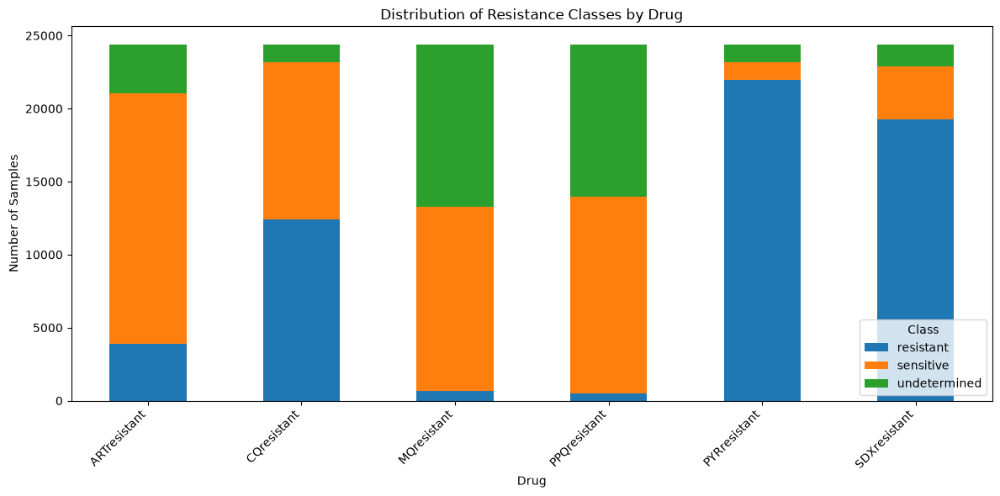

In [135]:
import matplotlib.pyplot as plt
import os

# Create folder
os.makedirs("../processed/target_distribution_plots", exist_ok=True)

# Count each class for each target
counts = target_df.apply(
    lambda col: col.value_counts(dropna=False)
).T

# Plot
counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Distribution of Resistance Classes by Drug")
plt.xlabel("Drug")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.tight_layout()

# Save as PNG
plt.savefig(
    "../processed/target_distribution_plots/resistance_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

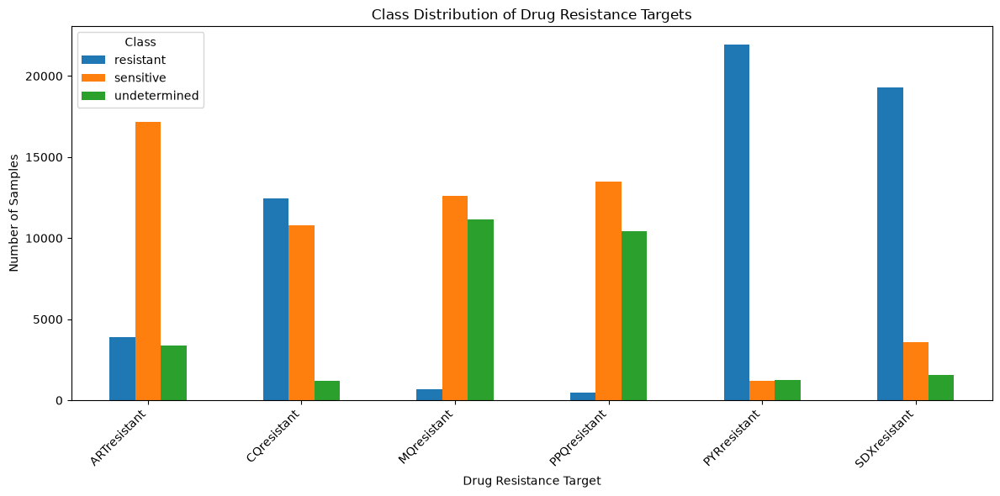

In [136]:
import matplotlib.pyplot as plt

counts = target_df.apply(
    lambda col: col.value_counts(dropna=False)
).T

ax = counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Class Distribution of Drug Resistance Targets")
plt.xlabel("Drug Resistance Target")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

### Encoding the y_target column

In [137]:
import numpy as np

Y = merged_encoded[target_col].replace({
    "sensitive": 0,
    "resistant": 1,
    "undetermined": 0
})

In [138]:
Y.head()

,ARTresistant,CQresistant,MQresistant,PPQresistant,PYRresistant,SDXresistant
0,0,0,0,0,0,0
1,0,1,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,0,1,0
4,0,1,0,0,1,0


## Encoding  variable  features

In [139]:
features_df = merged_encoded.drop(columns = target_col)

In [140]:
features_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24409 entries, 0 to 24408
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Sample              24409 non-null  str  
 1   crt_76[K]           24361 non-null  str  
 2   dhfr_108[S]         23995 non-null  str  
 3   dhps_437[G]         24139 non-null  str  
 4   dhfr_51[N]_assoc    24112 non-null  str  
 5   dhfr_59[C]_assoc    24085 non-null  str  
 6   dhfr_164[I]_assoc   24138 non-null  str  
 7   dhps_540[K]_assoc   21236 non-null  str  
 8   dhps_581[A]_assoc   24044 non-null  str  
 9   dhps_613[A]_assoc   24103 non-null  str  
 10  kelch13_known       4464 non-null   str  
 11  mdr1_dup_call       24409 non-null  str  
 12  pm2_dup_call        24409 non-null  str  
 13  cal_PYRresistant    23791 non-null  str  
 14  cal_SPresistant     23264 non-null  str  
 15  cal_ASMQresistant   24409 non-null  str  
 16  cal_dihydro_pi      24409 non-null  str  
 17  crt_

In [141]:
features_df.head()

,Sample,crt_76[K],dhfr_108[S],dhps_437[G],dhfr_51[N]_assoc,dhfr_59[C]_assoc,dhfr_164[I]_assoc,dhps_540[K]_assoc,dhps_581[A]_assoc,dhps_613[A]_assoc,...,mdr1_86[N],mdr1_184[Y],mdr1_1034[S],mdr1_1042[N],mdr1_1226[F],mdr1_1246[D],arps10_127-128[VD],fd_193[D],mdr2_484[T],sample_id
0,FP0008-C,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,FP0008-C
1,FP0009-C,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Rare,Rare,sensitive,sensitive,sensitive,Rare,sensitive,sensitive,sensitive,FP0009-C
2,FP0010-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Rare,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,FP0010-CW
3,FP0011-CW,Resistant,Resistant,Resistant,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,Rare,Rare,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,FP0011-CW
4,FP0012-CW,Resistant,Resistant,Sensitive,Resistant,Resistant,Sensitive,Sensitive,Sensitive,Sensitive,...,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,sensitive,FP0012-CW


In [142]:
features_df = features_df.drop(
    columns=["Sample", "sample_id"],
    errors="ignore"
).copy()

In [143]:
for col in features_df.columns:
    print(f"\n===== {col} =====")
    print(features_df[col].value_counts(dropna=False))


===== crt_76[K] =====
crt_76[K]
Resistant    13593
Sensitive    10768
NaN             48
Name: count, dtype: int64

===== dhfr_108[S] =====
dhfr_108[S]
Resistant    22780
Sensitive     1215
NaN            414
Name: count, dtype: int64

===== dhps_437[G] =====
dhps_437[G]
Resistant    20538
Sensitive     3601
NaN            270
Name: count, dtype: int64

===== dhfr_51[N]_assoc =====
dhfr_51[N]_assoc
Resistant    20083
Sensitive     4029
NaN            297
Name: count, dtype: int64

===== dhfr_59[C]_assoc =====
dhfr_59[C]_assoc
Resistant    22051
Sensitive     2034
NaN            324
Name: count, dtype: int64

===== dhfr_164[I]_assoc =====
dhfr_164[I]_assoc
Sensitive    19106
Resistant     5032
NaN            271
Name: count, dtype: int64

===== dhps_540[K]_assoc =====
dhps_540[K]_assoc
Sensitive    12850
Resistant     8386
NaN           3173
Name: count, dtype: int64

===== dhps_581[A]_assoc =====
dhps_581[A]_assoc
Sensitive    18695
Resistant     5349
NaN            365
Name: count, d

In [144]:
features_df = features_df[
    features_df['dhps_613[A]_assoc'] != "Other"
].copy()

In [145]:
for col in features_df.columns:
    print(f"\n===== {col} =====")
    print(features_df[col].value_counts(dropna=False))


===== crt_76[K] =====
crt_76[K]
Resistant    13593
Sensitive    10768
NaN             48
Name: count, dtype: int64

===== dhfr_108[S] =====
dhfr_108[S]
Resistant    22780
Sensitive     1215
NaN            414
Name: count, dtype: int64

===== dhps_437[G] =====
dhps_437[G]
Resistant    20538
Sensitive     3601
NaN            270
Name: count, dtype: int64

===== dhfr_51[N]_assoc =====
dhfr_51[N]_assoc
Resistant    20083
Sensitive     4029
NaN            297
Name: count, dtype: int64

===== dhfr_59[C]_assoc =====
dhfr_59[C]_assoc
Resistant    22051
Sensitive     2034
NaN            324
Name: count, dtype: int64

===== dhfr_164[I]_assoc =====
dhfr_164[I]_assoc
Sensitive    19106
Resistant     5032
NaN            271
Name: count, dtype: int64

===== dhps_540[K]_assoc =====
dhps_540[K]_assoc
Sensitive    12850
Resistant     8386
NaN           3173
Name: count, dtype: int64

===== dhps_581[A]_assoc =====
dhps_581[A]_assoc
Sensitive    18695
Resistant     5349
NaN            365
Name: count, d

In [146]:
features_df['crt_371[R]'].value_counts()

crt_371[R]
Rare         12455
sensitive    11954
Name: count, dtype: int64

### Encoding the X features

In [147]:
# defining different columns 
known_cols = list(marker_info.keys())
known_cols.append("mdr1_dup_call")
known_cols.append("pm2_dup_call")
#known_cols.append("cal_dihydro_pi") # calculated can lead to data leakage
#known_cols.append("cal_ASMQresistant")
#known_cols.append("cal_SPresistant")
#known_cols.append("cal_PYRresistant")


associated_cols = list(associated_marker.keys())

rare_cols = rare_col

In [148]:
print("Known:", known_cols)
print("Associated:", associated_cols)
print("Rare:", rare_cols)

Known: ['crt_76[K]', 'dhfr_108[S]', 'dhps_437[G]', 'mdr1_dup_call', 'pm2_dup_call']
Associated: ['dhfr_51[N]', 'dhfr_59[C]', 'dhfr_164[I]', 'dhps_540[K]', 'dhps_581[A]', 'dhps_613[A]']
Rare: ['crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]', 'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]', 'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_306[S]', 'dhps_436[S]', 'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]', 'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]', 'fd_193[D]', 'mdr2_484[T]']


In [149]:
known_cols.append("mdr1_dup_call")
known_cols.append("pm2_dup_call")

In [150]:
print("Rare:", rare_cols)

Rare: ['crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]', 'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]', 'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_306[S]', 'dhps_436[S]', 'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]', 'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]', 'fd_193[D]', 'mdr2_484[T]']


In [151]:
print([c for c in features_df.columns if 'dhfr' in c or 'dhps' in c])

['dhfr_108[S]', 'dhps_437[G]', 'dhfr_51[N]_assoc', 'dhfr_59[C]_assoc', 'dhfr_164[I]_assoc', 'dhps_540[K]_assoc', 'dhps_581[A]_assoc', 'dhps_613[A]_assoc', 'dhfr_16[N]', 'dhfr_306[S]', 'dhps_436[S]']


In [152]:
assoc_col = [c for c in encoded.columns if '_assoc' in c]

In [153]:
# encoding known and associated columns

X_known = features_df[known_cols].replace({
    "Resistant": 0.7,
    "Sensitive": 0,
    "sensitive": 0,
    "rare": 0.2,
    "Other":0
})

X_associated = features_df[assoc_col].replace({
    "Resistant": 1,
    "Sensitive": 0,
    "sensitive": 0,
    "rare": 0.2
})

In [154]:
# viewing columns associated with known resistance
for col in known_cols:
    print(col, X_known[col].value_counts(dropna=False))

crt_76[K] crt_76[K]
0.7    13593
0      10768
NaN       48
Name: count, dtype: int64
dhfr_108[S] dhfr_108[S]
0.7    22780
0       1215
NaN      414
Name: count, dtype: int64
dhps_437[G] dhps_437[G]
0.7    20538
0       3601
NaN      270
Name: count, dtype: int64


ValueError: Grouper for 'mdr1_dup_call' not 1-dimensional

In [ ]:
# viewing columns assocciated with resistance associations
for col in assoc_col:
    print(col, X_associated[col].value_counts(dropna=False))

dhfr_51[N]_assoc dhfr_51[N]_assoc
1      20083
0       4029
NaN      297
Name: count, dtype: int64
dhfr_59[C]_assoc dhfr_59[C]_assoc
1      22051
0       2034
NaN      324
Name: count, dtype: int64
dhfr_164[I]_assoc dhfr_164[I]_assoc
0      19106
1       5032
NaN      271
Name: count, dtype: int64
dhps_540[K]_assoc dhps_540[K]_assoc
0      12850
1       8386
NaN     3173
Name: count, dtype: int64
dhps_581[A]_assoc dhps_581[A]_assoc
0      18695
1       5349
NaN      365
Name: count, dtype: int64
dhps_613[A]_assoc dhps_613[A]_assoc
0      22744
1       1359
NaN      306
Name: count, dtype: int64


In [ ]:
print(type(rare_cols))
print(rare_cols)

<class 'list'>
['crt_72[C]', 'crt_74[M]', 'crt_75[N]', 'crt_93[T]', 'crt_97[H]', 'crt_218[I]', 'crt_220[A]', 'crt_271[Q]', 'crt_326[N]', 'crt_333[T]', 'crt_353[G]', 'crt_356[I]', 'crt_371[R]', 'dhfr_16[N]', 'dhfr_306[S]', 'dhps_436[S]', 'exo_415[E]', 'mdr1_86[N]', 'mdr1_184[Y]', 'mdr1_1034[S]', 'mdr1_1042[N]', 'mdr1_1226[F]', 'mdr1_1246[D]', 'arps10_127-128[VD]', 'fd_193[D]', 'mdr2_484[T]']


In [ ]:
# Handling rare mutations
X_rare = features_df[rare_cols].replace({
    "sensitive": 0,
    "Sensitive": 0,
    "Rare": 0.2,
    
})

In [ ]:
# merging all three
#X = pd.concat([ X_rare, X_associated,X_known],axis=1)

#print("X shape:", X.shape)
#X.head()

In [ ]:
# merging  when  dealing with X_rare and X_known only
X = pd.concat([ X_rare, X_associated],axis=1)

#print("X shape:", X.shape)
#X.head()

In [ ]:
# when dealing with rare column only
#X = X_rare.copy()

In [ ]:
X.shape

(24409, 32)

In [ ]:
Y.shape

(24409, 6)

In [ ]:
y = Y.apply(pd.to_numeric, errors="coerce")

In [ ]:
X = X.apply(pd.to_numeric, errors="coerce")

# Model

In [ ]:
mask = Y.notna().all(axis=1)

X_model = X.loc[mask]
y_model = Y.loc[mask]

print(X_model.shape)
print(y_model.shape)

(24409, 32)
(24409, 6)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42
)

In [ ]:
mask = y.notna().all(axis=1)

X_model = X.loc[mask].copy()
y_model = y.loc[mask].copy()

In [ ]:
print("X:", X_model.shape)
print("y:", y_model.shape)

print(y_model.dtypes)
print(y_model.apply(lambda x: x.unique()))

X: (24409, 32)
y: (24409, 6)
ARTresistant    int64
CQresistant     int64
MQresistant     int64
PPQresistant    int64
PYRresistant    int64
SDXresistant    int64
dtype: object
   ARTresistant  CQresistant  MQresistant  PPQresistant  PYRresistant  \
0             0            0            0             0             0   
1             1            1            1             1             1   

   SDXresistant  
0             0  
1             1  


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target

# Create a fresh train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42
)

# Check the target
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("y_train dtype:")
print(y_train.dtypes)

print("\nTarget type:")
print(type_of_target(y_train))

X_train: (19527, 32)
y_train: (19527, 6)
y_train dtype:
ARTresistant    int64
CQresistant     int64
MQresistant     int64
PPQresistant    int64
PYRresistant    int64
SDXresistant    int64
dtype: object

Target type:
multilabel-indicator


In [ ]:
from sklearn.utils.multiclass import type_of_target

print(type_of_target(y_model))

multilabel-indicator


## RandomForest classification

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print(y_pred.shape)
from sklearn.metrics import classification_report

for i, drug in enumerate(y.columns):
    print(f"\n===== {drug} ===rf==")
    print(
        classification_report(
            y_test.iloc[:, i],
            y_pred[:, i]
        )
    )
#self
y_self_pred = rf.predict(X_train)
for i, drug in enumerate(y.columns):
    print(f"\n===== {drug} ==rf===")
    print(
        classification_report(
            y_train.iloc[:, i],
            y_self_pred[:, i]
        )
    )


(4882, 6)

===== ARTresistant ===rf==
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4071
           1       0.88      0.88      0.88       811

    accuracy                           0.96      4882
   macro avg       0.93      0.93      0.93      4882
weighted avg       0.96      0.96      0.96      4882


===== CQresistant ===rf==
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      2399
           1       0.94      0.99      0.96      2483

    accuracy                           0.96      4882
   macro avg       0.96      0.96      0.96      4882
weighted avg       0.96      0.96      0.96      4882


===== MQresistant ===rf==
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4756
           1       0.60      0.54      0.57       126

    accuracy                           0.98      4882
   macro avg       0.79      0.77   

### Using weights with Randomforest

In [ ]:
rf_models = {}
y_pred_rf = {}

for drug in y_train.columns:

    n0 = (y_train[drug] == 0).sum()
    n1 = (y_train[drug] == 1).sum()

    weight = n0 / n1

    rf_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train, y_train[drug])

    rf_models[drug] = rf_model
    y_pred_rf[drug] = rf_model.predict(X_test)

In [ ]:
# determining AUC of the randomforest algorithm to determine if there is overfitting 
from sklearn.metrics import average_precision_score

for drug, model in rf_models.items():

    train_prob = model.predict_proba(X_train)[:, 1]
    test_prob = model.predict_proba(X_test)[:, 1]

    train_pr_auc = average_precision_score(
        y_train[drug],
        train_prob
    )

    test_pr_auc = average_precision_score(
        y_test[drug],
        test_prob
    )

    print(
        f"{drug}: "
        f"Train PR-AUC = {train_pr_auc:.3f}, "
        f"Test PR-AUC = {test_pr_auc:.3f}"
    )

ARTresistant: Train PR-AUC = 0.921, Test PR-AUC = 0.938
CQresistant: Train PR-AUC = 0.989, Test PR-AUC = 0.987
MQresistant: Train PR-AUC = 0.491, Test PR-AUC = 0.542
PPQresistant: Train PR-AUC = 0.334, Test PR-AUC = 0.426
PYRresistant: Train PR-AUC = 0.991, Test PR-AUC = 0.990
SDXresistant: Train PR-AUC = 0.960, Test PR-AUC = 0.962


## XGBoost

In [ ]:
#%pip install xgboost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
# preprocessing data for modeling (changing column names)
X_xgb = X_model.copy()

X_xgb.columns = (
    X_xgb.columns
    .str.replace("[", "_", regex=False)
    .str.replace("]", "_", regex=False)
    .str.replace("<", "_", regex=False)
)

print(X_xgb.columns.tolist())

['crt_72_C_', 'crt_74_M_', 'crt_75_N_', 'crt_93_T_', 'crt_97_H_', 'crt_218_I_', 'crt_220_A_', 'crt_271_Q_', 'crt_326_N_', 'crt_333_T_', 'crt_353_G_', 'crt_356_I_', 'crt_371_R_', 'dhfr_16_N_', 'dhfr_306_S_', 'dhps_436_S_', 'exo_415_E_', 'mdr1_86_N_', 'mdr1_184_Y_', 'mdr1_1034_S_', 'mdr1_1042_N_', 'mdr1_1226_F_', 'mdr1_1246_D_', 'arps10_127-128_VD_', 'fd_193_D_', 'mdr2_484_T_', 'dhfr_51_N__assoc', 'dhfr_59_C__assoc', 'dhfr_164_I__assoc', 'dhps_540_K__assoc', 'dhps_581_A__assoc', 'dhps_613_A__assoc']


In [ ]:
#splitting data into test and train
from sklearn.model_selection import train_test_split

X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X_xgb,
    y_model,
    test_size=0.2,
    random_state=42
)

In [ ]:
# creating a model, training it and using it for prediction
from xgboost import XGBClassifier

xgb_models = {}
y_pred_xgb = {}

for drug in y.columns:

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_xgb,
        y_train_xgb[drug]
    )

    xgb_models[drug] = model
    y_pred_xgb[drug] = model.predict(X_test_xgb)

In [ ]:
from sklearn.metrics import classification_report

for drug in y.columns:

    print(f"\n===== {drug} =xgb====")

    print(
        classification_report(
            y_test_xgb[drug],
            y_pred_xgb[drug]
        )
    )


===== ARTresistant =xgb====
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      4071
           1       0.88      0.86      0.87       811

    accuracy                           0.96      4882
   macro avg       0.93      0.92      0.92      4882
weighted avg       0.96      0.96      0.96      4882


===== CQresistant =xgb====
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      2399
           1       0.94      1.00      0.97      2483

    accuracy                           0.96      4882
   macro avg       0.97      0.96      0.96      4882
weighted avg       0.97      0.96      0.96      4882


===== MQresistant =xgb====
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4756
           1       0.64      0.46      0.54       126

    accuracy                           0.98      4882
   macro avg       0.82      0.73      0.76

In [ ]:
# calculating the AUC
from sklearn.metrics import average_precision_score

for drug, model in xgb_models.items():

    # Probabilities
    train_prob = model.predict_proba(X_train_xgb)[:, 1]
    test_prob = model.predict_proba(X_test_xgb)[:, 1]

    # PR-AUC
    train_pr_auc = average_precision_score(
        y_train_xgb[drug],
        train_prob
    )

    test_pr_auc = average_precision_score(
        y_test_xgb[drug],
        test_prob
    )

    print(
        f"{drug}: "
        f"Train PR-AUC = {train_pr_auc:.3f}, "
        f"Test PR-AUC = {test_pr_auc:.3f}"
    )


ARTresistant: Train PR-AUC = 0.943, Test PR-AUC = 0.939
CQresistant: Train PR-AUC = 0.992, Test PR-AUC = 0.988
MQresistant: Train PR-AUC = 0.537, Test PR-AUC = 0.555
PPQresistant: Train PR-AUC = 0.538, Test PR-AUC = 0.492
PYRresistant: Train PR-AUC = 0.993, Test PR-AUC = 0.990
SDXresistant: Train PR-AUC = 0.969, Test PR-AUC = 0.966


### XGboost with weights 

In [ ]:
# creating weights
for drug in y_train.columns:
    n0 = (y_train_xgb[drug] == 0).sum()
    n1 = (y_train_xgb[drug] == 1).sum()

    print(
        f"{drug}: "
        f"0={n0}, "
        f"1={n1}, "
        f"scale_pos_weight={n0/n1:.2f}"
    )

ARTresistant: 0=16433, 1=3094, scale_pos_weight=5.31
CQresistant: 0=9578, 1=9949, scale_pos_weight=0.96
MQresistant: 0=18995, 1=532, scale_pos_weight=35.70
PPQresistant: 0=19167, 1=360, scale_pos_weight=53.24
PYRresistant: 0=1942, 1=17585, scale_pos_weight=0.11
SDXresistant: 0=4103, 1=15424, scale_pos_weight=0.27


In [ ]:
xgb_w_models = {}
y_pred_xgb = {}

for drug in y_train_xgb.columns:

    n0 = (y_train_xgb[drug] == 0).sum()
    n1 = (y_train_xgb[drug] == 1).sum()

    weight = n0 / n1

    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_xgb, y_train_xgb[drug])

    xgb_w_models[drug] = model
    y_pred_xgb[drug] = model.predict(X_test_xgb)

In [ ]:
xgb_w_models

{'ARTresistant': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.8, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=0.05, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=4, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=300, n_jobs=-1,
               num_parallel_tree=None, ...),
 'CQresistant': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.8, device=None, early_stop

In [ ]:
from sklearn.metrics import classification_report

for drug in y.columns:
    print(f"\n===== {drug} ===xgbs_weights==")
    print(
        classification_report(
            y_test_xgb[drug],
            y_pred_xgb[drug]
        )
    )


===== ARTresistant ===xgbs_weights==
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      4071
           1       0.72      0.98      0.83       811

    accuracy                           0.93      4882
   macro avg       0.86      0.95      0.89      4882
weighted avg       0.95      0.93      0.94      4882


===== CQresistant ===xgbs_weights==
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      2399
           1       0.94      1.00      0.96      2483

    accuracy                           0.96      4882
   macro avg       0.97      0.96      0.96      4882
weighted avg       0.97      0.96      0.96      4882


===== MQresistant ===xgbs_weights==
              precision    recall  f1-score   support

           0       1.00      0.93      0.97      4756
           1       0.28      0.96      0.43       126

    accuracy                           0.94      4882
   macro avg    

### probabilities

In [ ]:
from sklearn.metrics import average_precision_score

for drug, model in xgb_w_models.items():

    # Probabilities
    train_prob = model.predict_proba(X_train_xgb)[:, 1]
    test_prob = model.predict_proba(X_test_xgb)[:, 1]

    # PR-AUC
    train_pr_auc = average_precision_score(
        y_train_xgb[drug],
        train_prob
    )

    test_pr_auc = average_precision_score(
        y_test_xgb[drug],
        test_prob
    )

    print(
        f"{drug}: "
        f"Train PR-AUC = {train_pr_auc:.3f}, "
        f"Test PR-AUC = {test_pr_auc:.3f}"
    )

ARTresistant: Train PR-AUC = 0.930, Test PR-AUC = 0.942
CQresistant: Train PR-AUC = 0.990, Test PR-AUC = 0.988
MQresistant: Train PR-AUC = 0.501, Test PR-AUC = 0.532
PPQresistant: Train PR-AUC = 0.463, Test PR-AUC = 0.492
PYRresistant: Train PR-AUC = 0.992, Test PR-AUC = 0.990
SDXresistant: Train PR-AUC = 0.965, Test PR-AUC = 0.965


In [ ]:
for drug in y_test.columns:

    prevalence = y_test_xgb[drug].mean()

    print(
        f"{drug}: "
        f"Positive prevalence = {prevalence:.3f}"
    )

ARTresistant: Positive prevalence = 0.166
CQresistant: Positive prevalence = 0.509
MQresistant: Positive prevalence = 0.026
PPQresistant: Positive prevalence = 0.026
PYRresistant: Positive prevalence = 0.897
SDXresistant: Positive prevalence = 0.788


In [ ]:
import pandas as pd

feature_importance = {}

for drug, model in xgb_w_models.items():

    importance = pd.Series(
        model.feature_importances_,
        index=X_train_xgb.columns
    ).sort_values(ascending=False)

    feature_importance[drug] = importance

    print(f"\n===== {drug} =====")
    print(importance.head(20))


===== ARTresistant =====
arps10_127-128_VD_    0.573772
crt_326_N_            0.110912
fd_193_D_             0.105110
exo_415_E_            0.030438
mdr2_484_T_           0.022579
crt_74_M_             0.016129
dhfr_164_I__assoc     0.014198
dhps_540_K__assoc     0.009616
dhfr_51_N__assoc      0.008867
crt_75_N_             0.008373
crt_356_I_            0.008060
crt_271_Q_            0.007670
mdr1_184_Y_           0.007439
crt_333_T_            0.006332
dhps_581_A__assoc     0.006139
dhfr_306_S_           0.005950
mdr1_1226_F_          0.005615
dhps_436_S_           0.005229
crt_371_R_            0.005200
dhps_613_A__assoc     0.004897
dtype: float32

===== CQresistant =====
crt_220_A_            0.666406
crt_75_N_             0.193377
fd_193_D_             0.019793
mdr2_484_T_           0.017930
crt_271_Q_            0.016211
arps10_127-128_VD_    0.013413
crt_72_C_             0.010808
crt_326_N_            0.009968
crt_356_I_            0.005910
mdr1_184_Y_           0.005423
crt_

In [ ]:
from sklearn.metrics import mutual_info_score

mi_results = []

for drug in y_train_xgb.columns:

    for feature in X_train_xgb.columns:

        x = X_train_xgb[feature].fillna(-1)

        mi = mutual_info_score(
            x,
            y_train_xgb[drug]
        )

        mi_results.append({
            "Drug": drug,
            "Feature": feature,
            "MutualInformation": mi
        })

mi_df = pd.DataFrame(mi_results)

mi_df.sort_values(
    ["Drug", "MutualInformation"],
    ascending=[True, False]
).head(30)

/home/ndono_work/miniforge3/envs/jp/lib/python3.14/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/home/ndono_work/miniforge3/envs/jp/lib/python3.14/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/home/ndono_work/miniforge3/envs/jp/lib/python3.14/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/home/ndono_work/miniforge3/envs/jp/lib/python3.14/site-packages/sklearn/metrics/cluster/_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous value

,Drug,Feature,MutualInformation
23,ARTresistant,arps10_127-128_VD_,0.247542
24,ARTresistant,fd_193_D_,0.231146
8,ARTresistant,crt_326_N_,0.214209
25,ARTresistant,mdr2_484_T_,0.185197
29,ARTresistant,dhps_540_K__assoc,0.183548
16,ARTresistant,exo_415_E_,0.166269
28,ARTresistant,dhfr_164_I__assoc,0.151826
11,ARTresistant,crt_356_I_,0.146232
30,ARTresistant,dhps_581_A__assoc,0.139885
1,ARTresistant,crt_74_M_,0.106072


In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    average_precision_score
)

report_lines = []

report_lines.append("XGBOOST WEIGHTED MODEL REPORT")
report_lines.append("=" * 80)
report_lines.append("")

for drug, model in xgb_w_models.items():

    # Predictions
    y_pred_train = model.predict(X_train_xgb)
    y_pred_test = model.predict(X_test_xgb)

    # Probabilities
    y_prob_train = model.predict_proba(X_train_xgb)[:, 1]
    y_prob_test = model.predict_proba(X_test_xgb)[:, 1]

    # PR-AUC
    train_pr_auc = average_precision_score(
        y_train[drug],
        y_prob_train
    )

    test_pr_auc = average_precision_score(
        y_test[drug],
        y_prob_test
    )

    # Prevalence
    prevalence = y_test[drug].mean()

    # Weight
    n0 = (y_train[drug] == 0).sum()
    n1 = (y_train[drug] == 1).sum()
    weight = n0 / n1

    # Header
    report_lines.append("=" * 80)
    report_lines.append(f"{drug}")
    report_lines.append("=" * 80)
    report_lines.append("X_rare ,associated and known undetermied    rare = 0.2")

    report_lines.append("")
    report_lines.append("MODEL PARAMETERS")
    report_lines.append("-" * 40)
    report_lines.append(f"n_estimators      : {model.n_estimators}")
    report_lines.append(f"max_depth         : {model.max_depth}")
    report_lines.append(f"learning_rate     : {model.learning_rate}")
    report_lines.append(f"subsample         : {model.subsample}")
    report_lines.append(f"colsample_bytree  : {model.colsample_bytree}")
    report_lines.append(f"scale_pos_weight  : {weight:.4f}")

    report_lines.append("")
    report_lines.append("DATA")
    report_lines.append("-" * 40)
    report_lines.append(f"Training samples  : {len(y_train[drug])}")
    report_lines.append(f"Test samples      : {len(y_test[drug])}")
    report_lines.append(f"Positive samples  : {n1}")
    report_lines.append(f"Negative samples  : {n0}")
    report_lines.append(f"Test prevalence   : {prevalence:.4f}")

    report_lines.append("")
    report_lines.append("PR-AUC")
    report_lines.append("-" * 40)
    report_lines.append(f"Train PR-AUC      : {train_pr_auc:.4f}")
    report_lines.append(f"Test PR-AUC       : {test_pr_auc:.4f}")
    report_lines.append(
        f"Difference        : {test_pr_auc - train_pr_auc:.4f}"
    )

    report_lines.append("")
    report_lines.append("TEST CLASSIFICATION REPORT")
    report_lines.append("-" * 40)
    report_lines.append(
        classification_report(
            y_test[drug],
            y_pred_test,
            digits=4
        )
    )

    report_lines.append("")
    report_lines.append(
        f"Test Accuracy     : {accuracy_score(y_test[drug], y_pred_test):.4f}"
    )

    report_lines.append("")


# Save report
report_path = "../data/processed/xgboost_weighted_model_report_5.txt"

with open(report_path, "w") as f:
    f.write("\n".join(report_lines))

print(f"Report saved as: {report_path}")

Report saved as: ../data/processed/xgboost_weighted_model_report_5.txt


In [ ]:
from sklearn.metrics import average_precision_score

for drug, model in xgb_models.items():

    # Predict probabilities using ALL X features
    train_prob = model.predict_proba(X_train_xgb)[:, 1]
    test_prob = model.predict_proba(X_test_xgb)[:, 1]

    # PR-AUC
    train_pr_auc = average_precision_score(
        y_train_xgb[drug],
        train_prob
    )

    test_pr_auc = average_precision_score(
        y_test_xgb[drug],
        test_prob
    )

    print(
        f"{drug}: "
        f"Train PR-AUC = {train_pr_auc:.3f}, "
        f"Test PR-AUC = {test_pr_auc:.3f}"
    )

ARTresistant: Train PR-AUC = 0.943, Test PR-AUC = 0.939
CQresistant: Train PR-AUC = 0.992, Test PR-AUC = 0.988
MQresistant: Train PR-AUC = 0.537, Test PR-AUC = 0.555
PPQresistant: Train PR-AUC = 0.538, Test PR-AUC = 0.492
PYRresistant: Train PR-AUC = 0.993, Test PR-AUC = 0.990
SDXresistant: Train PR-AUC = 0.969, Test PR-AUC = 0.966


In [ ]:
from sklearn.metrics import precision_recall_curve, f1_score

for drug, model in xgb_models.items():

    prob = model.predict_proba(X_test_xgb)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test_xgb[drug],
        prob
    )

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = f1.argmax()
    best_threshold = thresholds[best_idx]

    print(
        drug,
        "best threshold =", round(best_threshold, 3),
        "best F1 =", round(f1[best_idx], 3)
    )

ARTresistant best threshold = 0.428 best F1 = 0.881
CQresistant best threshold = 0.536 best F1 = 0.965
MQresistant best threshold = 0.247 best F1 = 0.595
PPQresistant best threshold = 0.3 best F1 = 0.487
PYRresistant best threshold = 0.39 best F1 = 0.973
SDXresistant best threshold = 0.525 best F1 = 0.913


In [ ]:
ppq_model = xgb_models["PPQresistant"]

In [ ]:
ppq_prob = ppq_model.predict_proba(X_test_xgb)[:, 1]

In [ ]:
from sklearn.metrics import f1_score
import numpy as np

thresholds = np.arange(0.1, 0.95, 0.05)

for threshold in thresholds:

    ppq_pred = (ppq_prob >= threshold).astype(int)

    f1 = f1_score(
        y_test_xgb["PPQresistant"],
        ppq_pred,
        zero_division=0
    )

    print(f"Threshold: {threshold:.2f} | F1: {f1:.3f}")

Threshold: 0.10 | F1: 0.446
Threshold: 0.15 | F1: 0.460
Threshold: 0.20 | F1: 0.471
Threshold: 0.25 | F1: 0.472
Threshold: 0.30 | F1: 0.487
Threshold: 0.35 | F1: 0.453
Threshold: 0.40 | F1: 0.389
Threshold: 0.45 | F1: 0.331
Threshold: 0.50 | F1: 0.333
Threshold: 0.55 | F1: 0.335
Threshold: 0.60 | F1: 0.318
Threshold: 0.65 | F1: 0.275
Threshold: 0.70 | F1: 0.141
Threshold: 0.75 | F1: 0.116
Threshold: 0.80 | F1: 0.117
Threshold: 0.85 | F1: 0.104
Threshold: 0.90 | F1: 0.061


In [ ]:
print(
    classification_report(
        y_test_xgb["PPQresistant"],
        (ppq_prob >= 0.5).astype(int),
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      4754
           1       0.79      0.21      0.33       128

    accuracy                           0.98      4882
   macro avg       0.89      0.60      0.66      4882
weighted avg       0.97      0.98      0.97      4882



In [ ]:
from sklearn.metrics import average_precision_score, f1_score

pqq_train_prob = xgb_models["PPQresistant"].predict_proba(
    X_train_xgb
)[:, 1]

pqq_test_prob = xgb_models["PPQresistant"].predict_proba(
    X_test_xgb
)[:, 1]

print("Train PR-AUC:",
      average_precision_score(y_train_xgb["PPQresistant"], pqq_train_prob))

print("Test PR-AUC:",
      average_precision_score(y_test_xgb["PPQresistant"], pqq_test_prob))

Train PR-AUC: 0.538038476066153
Test PR-AUC: 0.4915899463153471


## validation

In [ ]:
xgb_ww_models = {}
y_pred_xgb = {}
y_prob_xgb = {}

for drug in y_train_xgb.columns:

    n0 = (y_train_xgb[drug] == 0).sum()
    n1 = (y_train_xgb[drug] == 1).sum()

    weight = n0 / n1

    model = XGBClassifier(
        n_estimators=1000,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        early_stopping_rounds=50,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_xgb,
        y_train_xgb[drug],
        eval_set=[(X_test_xgb, y_test_xgb[drug])],
        verbose=False
    )

    xgb_ww_models[drug] = model

    y_pred_xgb[drug] = model.predict(X_test_xgb)
    y_prob_xgb[drug] = model.predict_proba(X_test_xgb)[:, 1]

In [ ]:
from sklearn.metrics import average_precision_score

for drug, model in xgb_ww_models.items():

    # Predict probabilities using ALL X features
    train_prob = model.predict_proba(X_train_xgb)[:, 1]
    test_prob = model.predict_proba(X_test_xgb)[:, 1]

    # PR-AUC
    train_pr_auc = average_precision_score(
        y_train_xgb[drug],
        train_prob
    )

    test_pr_auc = average_precision_score(
        y_test_xgb[drug],
        test_prob
    )

    print(
        f"{drug}: "
        f"Train PR-AUC = {train_pr_auc:.3f}, "
        f"Test PR-AUC = {test_pr_auc:.3f}"
    )

ARTresistant: Train PR-AUC = 0.929, Test PR-AUC = 0.942
CQresistant: Train PR-AUC = 0.990, Test PR-AUC = 0.988
MQresistant: Train PR-AUC = 0.469, Test PR-AUC = 0.534
PPQresistant: Train PR-AUC = 0.378, Test PR-AUC = 0.443
PYRresistant: Train PR-AUC = 0.992, Test PR-AUC = 0.990
SDXresistant: Train PR-AUC = 0.965, Test PR-AUC = 0.965


### with validation

In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

xgb_www_models = {}
y_pred_xgb = {}
y_prob_xgb = {}

for drug in y_train_xgb.columns:

    # Split training data into train + validation
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_xgb,
        y_train_xgb[drug],
        test_size=0.2,
        stratify=y_train_xgb[drug],
        random_state=42
    )

    n0 = (y_tr == 0).sum()
    n1 = (y_tr == 1).sum()

    weight = n0 / n1

    model = XGBClassifier(
        n_estimators=1000,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        early_stopping_rounds=50,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    xgb_www_models[drug] = model

    # Final evaluation ONLY on untouched test set
    y_pred_xgb[drug] = model.predict(X_test_xgb)
    y_prob_xgb[drug] = model.predict_proba(X_test_xgb)[:, 1]

In [ ]:
from sklearn.metrics import average_precision_score

for drug, model in xgb_www_models.items():

    # Predict probabilities using ALL X features
    train_prob = model.predict_proba(X_train_xgb)[:, 1]
    test_prob = model.predict_proba(X_test_xgb)[:, 1]

    # PR-AUC
    train_pr_auc = average_precision_score(
        y_train_xgb[drug],
        train_prob
    )

    test_pr_auc = average_precision_score(
        y_test_xgb[drug],
        test_prob
    )

    print(
        f"{drug}: "
        f"Train PR-AUC = {train_pr_auc:.3f}, "
        f"Test PR-AUC = {test_pr_auc:.3f}"
    )

ARTresistant: Train PR-AUC = 0.919, Test PR-AUC = 0.934
CQresistant: Train PR-AUC = 0.989, Test PR-AUC = 0.987
MQresistant: Train PR-AUC = 0.466, Test PR-AUC = 0.520
PPQresistant: Train PR-AUC = 0.515, Test PR-AUC = 0.489
PYRresistant: Train PR-AUC = 0.992, Test PR-AUC = 0.990
SDXresistant: Train PR-AUC = 0.964, Test PR-AUC = 0.964


## cross validation

In [ ]:
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

# --------------------------------------------------
# 5-FOLD STRATIFIED CROSS-VALIDATION
# --------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

# Store information needed for final models
best_n_estimators = {}
cv_models = {}

for drug in y_train_xgb.columns:

    print(f"\n{'='*60}")
    print(f"{drug}")
    print(f"{'='*60}")

    X = X_train_xgb
    y = y_train_xgb[drug]

    fold_pr_auc = []
    fold_roc_auc = []
    fold_f1 = []
    fold_precision = []
    fold_recall = []

    fold_best_trees = []

    # --------------------------------------------------
    # 5 FOLDS
    # --------------------------------------------------

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X, y), start=1
    ):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # --------------------------------------------------
        # CLASS WEIGHT
        # --------------------------------------------------

        n0 = (y_tr == 0).sum()
        n1 = (y_tr == 1).sum()

        weight = n0 / n1

        # --------------------------------------------------
        # MODEL
        # --------------------------------------------------

        model = XGBClassifier(
            n_estimators=1000,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=weight,
            missing=float('nan'),
            objective="binary:logistic",
            eval_metric="aucpr",
            early_stopping_rounds=50,
            random_state=42,
            n_jobs=-1
        )

        # --------------------------------------------------
        # TRAIN
        # --------------------------------------------------

        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        # --------------------------------------------------
        # SAVE BEST NUMBER OF TREES
        # --------------------------------------------------

        best_tree = model.best_iteration + 1
        fold_best_trees.append(best_tree)

        # --------------------------------------------------
        # PREDICTIONS
        # --------------------------------------------------

        y_prob = model.predict_proba(X_val)[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)

        # --------------------------------------------------
        # METRICS
        # --------------------------------------------------

        pr_auc = average_precision_score(y_val, y_prob)
        roc_auc = roc_auc_score(y_val, y_prob)

        f1 = f1_score(
            y_val,
            y_pred,
            zero_division=0
        )

        precision = precision_score(
            y_val,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            zero_division=0
        )

        fold_pr_auc.append(pr_auc)
        fold_roc_auc.append(roc_auc)
        fold_f1.append(f1)
        fold_precision.append(precision)
        fold_recall.append(recall)

        print(
            f"Fold {fold}: "
            f"PR-AUC={pr_auc:.4f}, "
            f"ROC-AUC={roc_auc:.4f}, "
            f"F1={f1:.4f}, "
            f"Precision={precision:.4f}, "
            f"Recall={recall:.4f}, "
            f"Best trees={best_tree}"
        )

    # --------------------------------------------------
    # AVERAGE BEST NUMBER OF TREES
    # --------------------------------------------------

    final_trees = int(np.round(np.mean(fold_best_trees)))

    best_n_estimators[drug] = final_trees

    print("\nBest trees across folds:")
    print(fold_best_trees)

    print(f"Final n_estimators: {final_trees}")

    # --------------------------------------------------
    # MEAN ± SD
    # --------------------------------------------------

    print("\nMean ± SD")

    print(
        f"PR-AUC:    "
        f"{np.mean(fold_pr_auc):.4f} ± "
        f"{np.std(fold_pr_auc):.4f}"
    )

    print(
        f"ROC-AUC:   "
        f"{np.mean(fold_roc_auc):.4f} ± "
        f"{np.std(fold_roc_auc):.4f}"
    )

    print(
        f"F1:        "
        f"{np.mean(fold_f1):.4f} ± "
        f"{np.std(fold_f1):.4f}"
    )

    print(
        f"Precision:  "
        f"{np.mean(fold_precision):.4f} ± "
        f"{np.std(fold_precision):.4f}"
    )

    print(
        f"Recall:     "
        f"{np.mean(fold_recall):.4f} ± "
        f"{np.std(fold_recall):.4f}"
    )

    # --------------------------------------------------
    # SAVE CV RESULTS
    # --------------------------------------------------

    cv_results.append({

        "Drug": drug,

        "PR_AUC_mean": np.mean(fold_pr_auc),
        "PR_AUC_std": np.std(fold_pr_auc),

        "ROC_AUC_mean": np.mean(fold_roc_auc),
        "ROC_AUC_std": np.std(fold_roc_auc),

        "F1_mean": np.mean(fold_f1),
        "F1_std": np.std(fold_f1),

        "Precision_mean": np.mean(fold_precision),
        "Precision_std": np.std(fold_precision),

        "Recall_mean": np.mean(fold_recall),
        "Recall_std": np.std(fold_recall),

        "Best_trees": final_trees
    })


# --------------------------------------------------
# FINAL CV SUMMARY
# --------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)

cv_results_df


ARTresistant
Fold 1: PR-AUC=0.9230, ROC-AUC=0.9862, F1=0.8328, Precision=0.7299, Recall=0.9693, Best trees=322
Fold 2: PR-AUC=0.9138, ROC-AUC=0.9852, F1=0.8135, Precision=0.6975, Recall=0.9758, Best trees=199
Fold 3: PR-AUC=0.9267, ROC-AUC=0.9854, F1=0.8238, Precision=0.7189, Recall=0.9644, Best trees=448
Fold 4: PR-AUC=0.9163, ROC-AUC=0.9852, F1=0.8019, Precision=0.6830, Recall=0.9709, Best trees=96
Fold 5: PR-AUC=0.9259, ROC-AUC=0.9863, F1=0.8264, Precision=0.7313, Recall=0.9499, Best trees=869

Best trees across folds:
[322, 199, 448, 96, 869]
Final n_estimators: 387

Mean ± SD
PR-AUC:    0.9212 ± 0.0052
ROC-AUC:   0.9856 ± 0.0005
F1:        0.8197 ± 0.0109
Precision:  0.7121 ± 0.0190
Recall:     0.9661 ± 0.0089

CQresistant
Fold 1: PR-AUC=0.9894, ROC-AUC=0.9905, F1=0.9610, Precision=0.9275, Recall=0.9970, Best trees=231
Fold 2: PR-AUC=0.9896, ROC-AUC=0.9909, F1=0.9638, Precision=0.9328, Recall=0.9970, Best trees=215
Fold 3: PR-AUC=0.9854, ROC-AUC=0.9873, F1=0.9553, Precision=0.915

,Drug,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,ROC_AUC_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Best_trees
0,ARTresistant,0.921159,0.005187,0.985644,0.000483,0.819657,0.010854,0.712125,0.018967,0.966063,0.008851,387
1,CQresistant,0.987749,0.001646,0.989214,0.001334,0.960677,0.002878,0.927209,0.006164,0.996683,0.001477,218
2,MQresistant,0.484112,0.044774,0.975181,0.001781,0.398716,0.012895,0.252541,0.011065,0.949198,0.018570,116
3,PPQresistant,0.379864,0.021860,0.968930,0.005991,0.247619,0.013244,0.141985,0.008431,0.969444,0.023895,140
4,PYRresistant,0.989934,0.000974,0.926889,0.005303,0.901817,0.003453,0.978785,0.002775,0.836110,0.006790,186
5,SDXresistant,0.961417,0.002438,0.872356,0.006862,0.814402,0.006472,0.950388,0.004532,0.712526,0.009657,402


In [ ]:
## getting the final model
final_models = {}

for drug in y_train_xgb.columns:

    print(f"Training final model: {drug}")

    X = X_train_xgb
    y = y_train_xgb[drug]

    # ---------------------------------------------
    # CLASS WEIGHT FROM ALL TRAINING DATA
    # ---------------------------------------------

    n0 = (y == 0).sum()
    n1 = (y == 1).sum()

    weight = n0 / n1

    # ---------------------------------------------
    # NUMBER OF TREES FROM CROSS-VALIDATION
    # ---------------------------------------------

    n_trees = best_n_estimators[drug]

    # ---------------------------------------------
    # FINAL MODEL
    # ---------------------------------------------

    final_model = XGBClassifier(

        n_estimators=n_trees,

        max_depth=4,
        learning_rate=0.05,

        subsample=0.8,
        colsample_bytree=0.8,

        scale_pos_weight=weight,

        objective="binary:logistic",
        eval_metric="aucpr",

        random_state=42,
        n_jobs=-1
    )

    # ---------------------------------------------
    # TRAIN ON ALL TRAINING DATA
    # ---------------------------------------------

    final_model.fit(
        X,
        y,
        verbose=False
    )

    # ---------------------------------------------
    # SAVE MODEL
    # ---------------------------------------------

    final_models[drug] = final_model

Training final model: ARTresistant
Training final model: CQresistant
Training final model: MQresistant
Training final model: PPQresistant
Training final model: PYRresistant
Training final model: SDXresistant


In [ ]:
# getting important features 

feature_importance = {}

for drug, model in final_models.items():

    importance = pd.Series(
        model.feature_importances_,
        index=X_train_xgb.columns
    ).sort_values(ascending=False)

    feature_importance[drug] = importance

In [ ]:
for drug, importance in feature_importance.items():

    print(f"\n{'='*60}")
    print(drug)
    print(f"{'='*60}")

    print(importance.head(20))


ARTresistant
arps10_127-128_VD_    0.566543
crt_326_N_            0.114955
fd_193_D_             0.105829
exo_415_E_            0.031251
mdr2_484_T_           0.021990
crt_74_M_             0.016708
dhfr_164_I__assoc     0.014337
dhps_540_K__assoc     0.009434
dhfr_51_N__assoc      0.008809
crt_356_I_            0.008401
mdr1_184_Y_           0.007591
crt_333_T_            0.007208
crt_271_Q_            0.007096
crt_75_N_             0.006508
dhps_581_A__assoc     0.006321
dhfr_306_S_           0.005991
mdr1_1226_F_          0.005786
crt_371_R_            0.005365
dhps_613_A__assoc     0.005136
dhps_436_S_           0.004997
dtype: float32

CQresistant
crt_220_A_            0.631858
crt_75_N_             0.196075
mdr2_484_T_           0.026951
fd_193_D_             0.024580
crt_271_Q_            0.017099
arps10_127-128_VD_    0.017078
crt_326_N_            0.011276
crt_72_C_             0.010498
mdr1_184_Y_           0.007632
crt_356_I_            0.006824
crt_97_H_             0.0064

In [ ]:
def normalize_xgb_name(name):
    return (
        str(name)
        .replace("[", "_")
        .replace("]", "_")
        .replace("<", "_")
    )


known_xgb = {
    normalize_xgb_name(col)
    for col in known_cols
}

associated_xgb = {
    normalize_xgb_name(col) + "_assoc"
    for col in associated_cols
}

rare_xgb = {
    normalize_xgb_name(col)
    for col in rare_cols
}

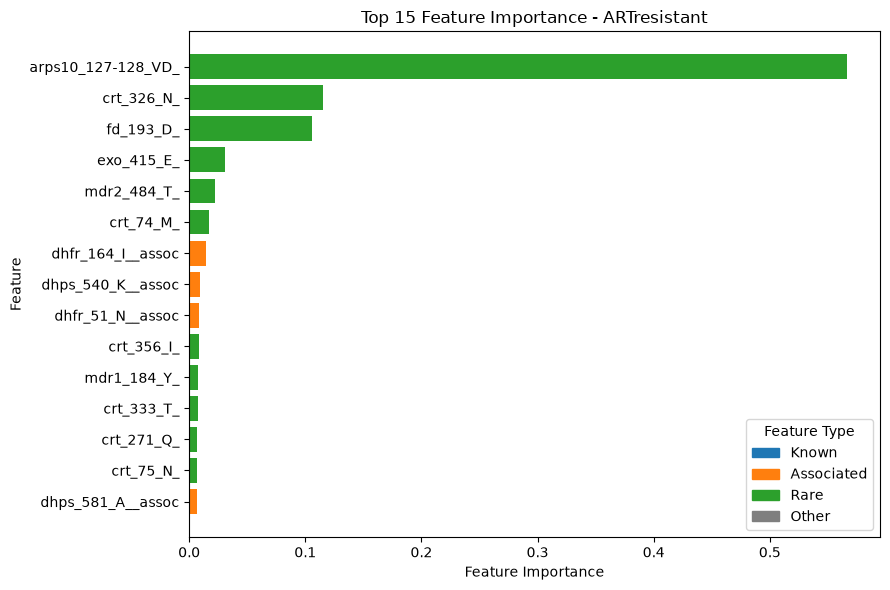

Saved: ../processed/feature_importance_plots/ARTresistant_association_rare_feature_importance.png


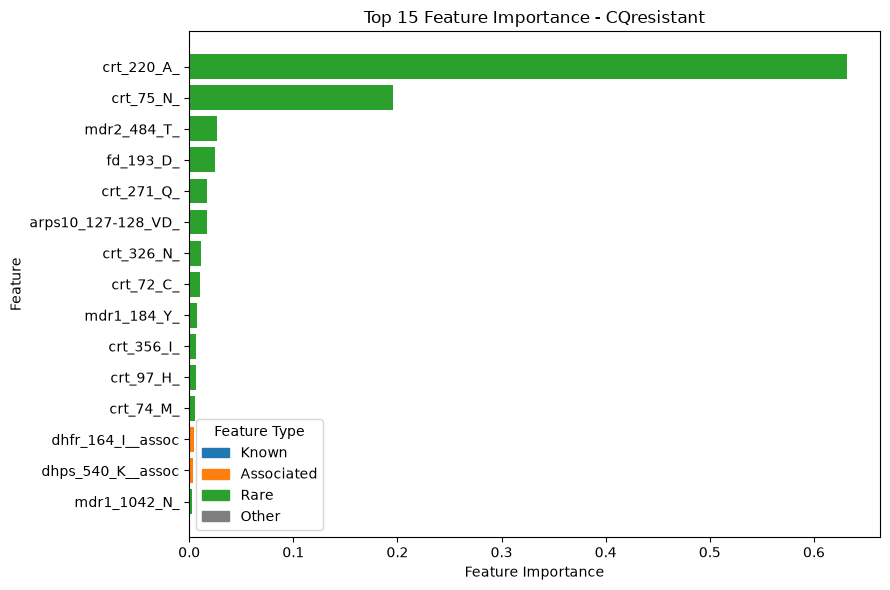

Saved: ../processed/feature_importance_plots/CQresistant_association_rare_feature_importance.png


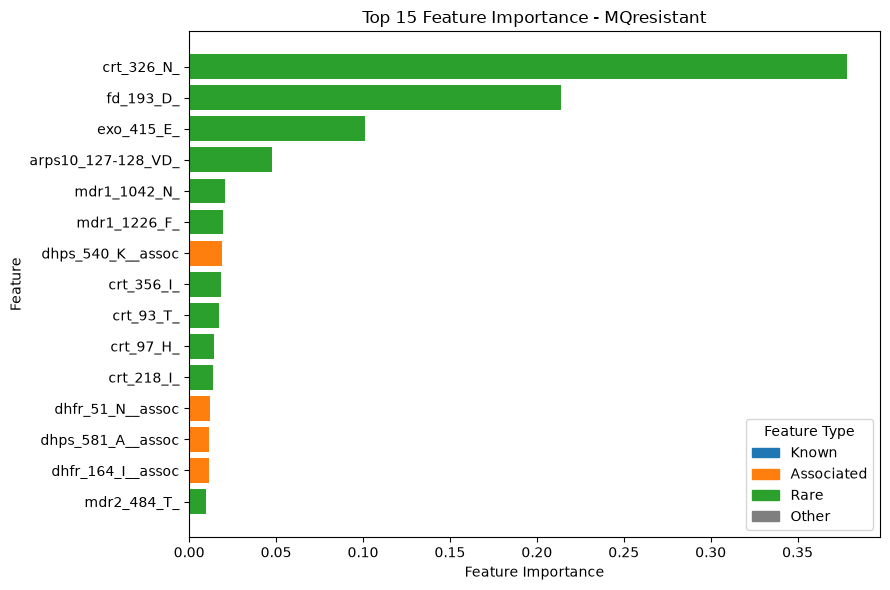

Saved: ../processed/feature_importance_plots/MQresistant_association_rare_feature_importance.png


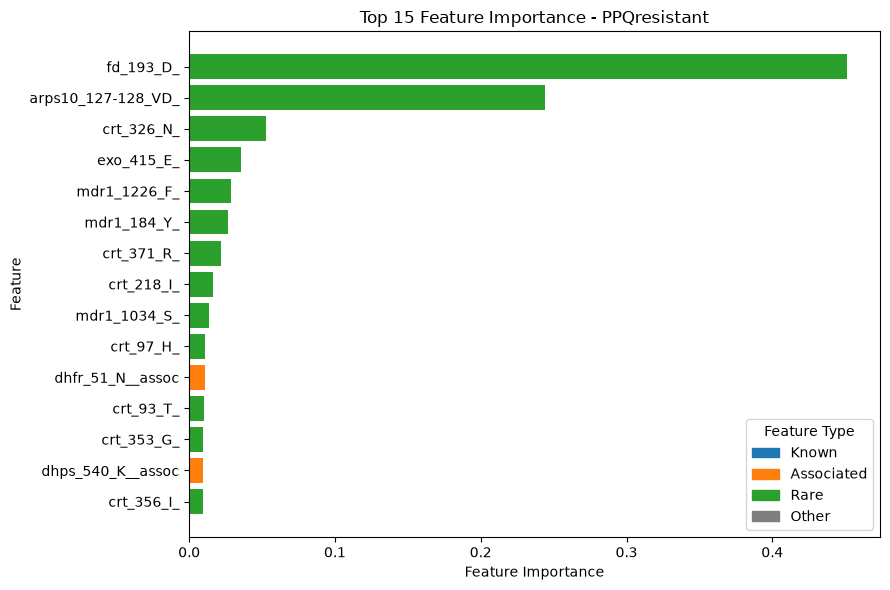

Saved: ../processed/feature_importance_plots/PPQresistant_association_rare_feature_importance.png


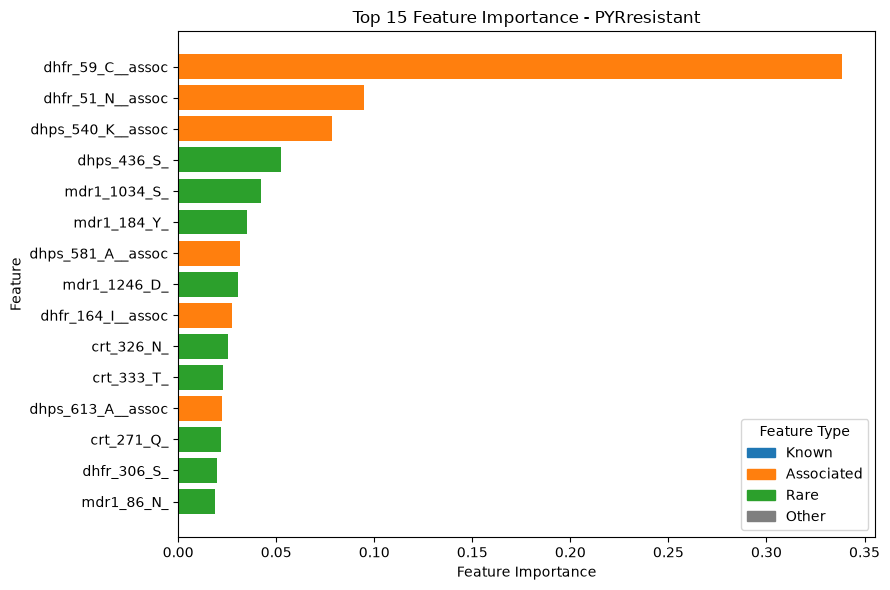

Saved: ../processed/feature_importance_plots/PYRresistant_association_rare_feature_importance.png


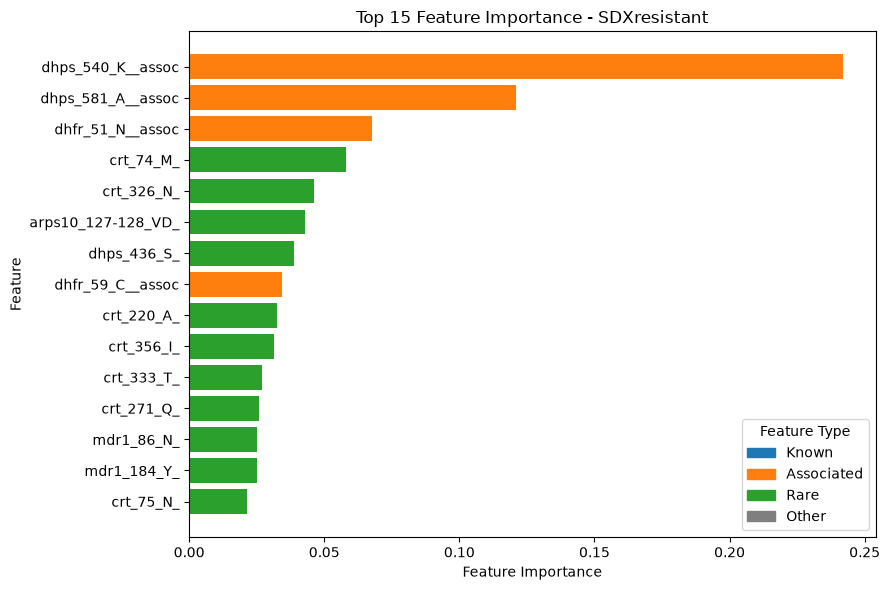

Saved: ../processed/feature_importance_plots/SDXresistant_association_rare_feature_importance.png


In [ ]:

# Create folder for plots
os.makedirs("../processed/feature_importance_plots", exist_ok=True)


# --------------------------------------------------
# Define feature category
# --------------------------------------------------

def get_feature_category(feature):

    feature = str(feature).strip()

    if feature in known_xgb:
        return "Known"

    elif feature in associated_xgb:
        return "Associated"

    elif feature in rare_xgb:
        return "Rare"

    else:
        return "Other"


# --------------------------------------------------
# Color mapping
# --------------------------------------------------

color_map = {
    "Known": "tab:blue",
    "Associated": "tab:orange",
    "Rare": "tab:green",
    "Other": "tab:gray"
}




# --------------------------------------------------
# Plot and save for every drug
# --------------------------------------------------

for drug, importance in feature_importance.items():

    # Top 15 features
    top_features = importance.head(15).sort_values()

    # Get category for each feature
    categories = [
        get_feature_category(feature)
        for feature in top_features.index
    ]

    # Get color for each feature
    colors = [
    color_map[get_feature_category(feature)]
    for feature in top_features.index]

    # Create figure
    plt.figure(figsize=(9, 6))

    plt.barh(
        top_features.index,
        top_features.values,
        color=colors
    )

    plt.title(f"Top 15 Feature Importance - {drug}")
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")

    # Legend
    legend_elements = [
        Patch(color="tab:blue", label="Known"),
        Patch(color="tab:orange", label="Associated"),
        Patch(color="tab:green", label="Rare"),
        Patch(color="tab:gray", label="Other")
    ]

    plt.legend(
        handles=legend_elements,
        title="Feature Type"
    )

    plt.tight_layout()

    # --------------------------------------------------
    # SAVE PNG
    # --------------------------------------------------

    filename = f"../processed/feature_importance_plots/{drug}_association_rare_feature_importance.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Close figure to prevent memory buildup
    plt.close()

    print(f"Saved: {filename}")

In [ ]:
for drug, importance in feature_importance.items():

    top_features = importance.head(15)

    print(f"\n{'='*60}")
    print(drug)

    for feature in top_features.index:
        category = get_feature_category(feature)

        if category == "Other":
            print("OTHER:", repr(feature))


ARTresistant

CQresistant

MQresistant

PPQresistant

PYRresistant

SDXresistant


## Using multilabel stratified Kfold

In [ ]:
#%pip install iterative-stratification

### with no weights

In [ ]:
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

# --------------------------------------------------
# 5-FOLD ITERATIVE MULTILABEL STRATIFICATION
# --------------------------------------------------

cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

best_n_estimators = {}
cv_models = {}

X = X_train_xgb
Y = y_train_xgb

# --------------------------------------------------
# GENERATE THE SAME MULTILABEL FOLDS
# --------------------------------------------------

folds = list(
    cv.split(X, Y)
)

# --------------------------------------------------
# RUN EACH DRUG
# --------------------------------------------------

for drug in Y.columns:

    print(f"\n{'='*60}")
    print(f"{drug}")
    print(f"{'='*60}")

    y = Y[drug]

    fold_pr_auc = []
    fold_roc_auc = []
    fold_f1 = []
    fold_precision = []
    fold_recall = []

    fold_best_trees = []

    # --------------------------------------------------
    # USE THE SAME ITERATIVE FOLDS
    # --------------------------------------------------

    for fold, (train_idx, val_idx) in enumerate(
        folds,
        start=1
    ):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # --------------------------------------------------
        # CLASS WEIGHT
        # --------------------------------------------------

        n0 = (y_tr == 0).sum()
        n1 = (y_tr == 1).sum()

        weight = n0 / n1

        # --------------------------------------------------
        # MODEL
        # --------------------------------------------------

        model = XGBClassifier(
            n_estimators=1000,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,

            scale_pos_weight=weight,

            objective="binary:logistic",
            eval_metric="aucpr",

            early_stopping_rounds=50,

            random_state=42,
            n_jobs=-1
        )

        # --------------------------------------------------
        # TRAIN
        # --------------------------------------------------

        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        # --------------------------------------------------
        # BEST TREES
        # --------------------------------------------------

        best_tree = model.best_iteration + 1

        fold_best_trees.append(best_tree)

        # --------------------------------------------------
        # PREDICTIONS
        # --------------------------------------------------

        y_prob = model.predict_proba(X_val)[:, 1]

        y_pred = (y_prob >= 0.5).astype(int)

        # --------------------------------------------------
        # METRICS
        # --------------------------------------------------

        pr_auc = average_precision_score(
            y_val,
            y_prob
        )

        roc_auc = roc_auc_score(
            y_val,
            y_prob
        )

        f1 = f1_score(
            y_val,
            y_pred,
            zero_division=0
        )

        precision = precision_score(
            y_val,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            zero_division=0
        )

        # --------------------------------------------------
        # STORE
        # --------------------------------------------------

        fold_pr_auc.append(pr_auc)
        fold_roc_auc.append(roc_auc)
        fold_f1.append(f1)
        fold_precision.append(precision)
        fold_recall.append(recall)

        print(
            f"Fold {fold}: "
            f"PR-AUC={pr_auc:.4f}, "
            f"ROC-AUC={roc_auc:.4f}, "
            f"F1={f1:.4f}, "
            f"Precision={precision:.4f}, "
            f"Recall={recall:.4f}, "
            f"Best trees={best_tree}"
        )

    # --------------------------------------------------
    # FINAL NUMBER OF TREES
    # --------------------------------------------------

    final_trees = int(
        np.round(
            np.mean(fold_best_trees)
        )
    )

    best_n_estimators[drug] = final_trees

    # --------------------------------------------------
    # PRINT SUMMARY
    # --------------------------------------------------

    print("\nBest trees across folds:")
    print(fold_best_trees)

    print(
        f"Final n_estimators: {final_trees}"
    )

    print("\nMean ± SD")

    print(
        f"PR-AUC:    "
        f"{np.mean(fold_pr_auc):.4f} ± "
        f"{np.std(fold_pr_auc):.4f}"
    )

    print(
        f"ROC-AUC:   "
        f"{np.mean(fold_roc_auc):.4f} ± "
        f"{np.std(fold_roc_auc):.4f}"
    )

    print(
        f"F1:        "
        f"{np.mean(fold_f1):.4f} ± "
        f"{np.std(fold_f1):.4f}"
    )

    print(
        f"Precision: "
        f"{np.mean(fold_precision):.4f} ± "
        f"{np.std(fold_precision):.4f}"
    )

    print(
        f"Recall:    "
        f"{np.mean(fold_recall):.4f} ± "
        f"{np.std(fold_recall):.4f}"
    )

    # --------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------

    cv_results.append({

        "Drug": drug,

        "PR_AUC_mean": np.mean(fold_pr_auc),
        "PR_AUC_std": np.std(fold_pr_auc),

        "ROC_AUC_mean": np.mean(fold_roc_auc),
        "ROC_AUC_std": np.std(fold_roc_auc),

        "F1_mean": np.mean(fold_f1),
        "F1_std": np.std(fold_f1),

        "Precision_mean": np.mean(fold_precision),
        "Precision_std": np.std(fold_precision),

        "Recall_mean": np.mean(fold_recall),
        "Recall_std": np.std(fold_recall),

        "Best_trees": final_trees
    })


# --------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)

cv_results_df


ARTresistant
Fold 1: PR-AUC=0.9160, ROC-AUC=0.9845, F1=0.8185, Precision=0.7066, Recall=0.9725, Best trees=183
Fold 2: PR-AUC=0.9337, ROC-AUC=0.9859, F1=0.8040, Precision=0.6869, Recall=0.9693, Best trees=146
Fold 3: PR-AUC=0.9084, ROC-AUC=0.9840, F1=0.8143, Precision=0.7090, Recall=0.9564, Best trees=267
Fold 4: PR-AUC=0.9218, ROC-AUC=0.9846, F1=0.8135, Precision=0.6975, Recall=0.9758, Best trees=234
Fold 5: PR-AUC=0.9120, ROC-AUC=0.9840, F1=0.8021, Precision=0.6778, Recall=0.9822, Best trees=84

Best trees across folds:
[183, 146, 267, 234, 84]
Final n_estimators: 183

Mean ± SD
PR-AUC:    0.9184 ± 0.0088
ROC-AUC:   0.9846 ± 0.0007
F1:        0.8105 ± 0.0063
Precision: 0.6956 ± 0.0118
Recall:    0.9712 ± 0.0086

CQresistant
Fold 1: PR-AUC=0.9854, ROC-AUC=0.9870, F1=0.9566, Precision=0.9198, Recall=0.9965, Best trees=267
Fold 2: PR-AUC=0.9887, ROC-AUC=0.9902, F1=0.9653, Precision=0.9334, Recall=0.9995, Best trees=222
Fold 3: PR-AUC=0.9888, ROC-AUC=0.9899, F1=0.9628, Precision=0.9318,

,Drug,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,ROC_AUC_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Best_trees
0,ARTresistant,0.918374,0.008849,0.984610,0.000696,0.810480,0.006315,0.695551,0.011785,0.971234,0.008575,183
1,CQresistant,0.987778,0.001251,0.989224,0.001163,0.961340,0.002868,0.928081,0.004865,0.997085,0.001471,238
2,MQresistant,0.480600,0.018043,0.975278,0.002198,0.395152,0.013581,0.249291,0.009500,0.953024,0.027234,93
3,PPQresistant,0.345304,0.041409,0.967385,0.005651,0.242144,0.009693,0.138304,0.005906,0.972222,0.023241,83
4,PYRresistant,0.989993,0.001296,0.927530,0.008374,0.902437,0.004394,0.979039,0.002690,0.836963,0.005920,213
5,SDXresistant,0.961597,0.000604,0.873272,0.002074,0.815278,0.002866,0.951650,0.003200,0.713109,0.004388,403


### with weights multilabelStratification Label

In [ ]:
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

# --------------------------------------------------
# 5-FOLD ITERATIVE MULTILABEL STRATIFICATION
# --------------------------------------------------

cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

best_n_estimators = {}
cv_models = {}

X = X_train_xgb
Y = y_train_xgb

# --------------------------------------------------
# GENERATE THE SAME MULTILABEL FOLDS
# --------------------------------------------------

folds = list(
    cv.split(X, Y)
)

# --------------------------------------------------
# RUN EACH DRUG
# --------------------------------------------------

for drug in Y.columns:

    print(f"\n{'='*60}")
    print(f"{drug}")
    print(f"{'='*60}")

    y = Y[drug]

    fold_pr_auc = []
    fold_roc_auc = []
    fold_f1 = []
    fold_precision = []
    fold_recall = []

    fold_best_trees = []

    # --------------------------------------------------
    # USE THE SAME ITERATIVE FOLDS
    # --------------------------------------------------

    for fold, (train_idx, val_idx) in enumerate(
        folds,
        start=1
    ):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # --------------------------------------------------
        # CLASS WEIGHT
        # --------------------------------------------------

        n0 = (y_tr == 0).sum()
        n1 = (y_tr == 1).sum()

        weight = n0 / n1

        # --------------------------------------------------
        # MODEL
        # --------------------------------------------------

        model = XGBClassifier(
            n_estimators=1000,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,

            objective="binary:logistic",
            eval_metric="aucpr",

            early_stopping_rounds=50,

            random_state=42,
            n_jobs=-1
        )

        # --------------------------------------------------
        # TRAIN
        # --------------------------------------------------

        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        # --------------------------------------------------
        # BEST TREES
        # --------------------------------------------------

        best_tree = model.best_iteration + 1

        fold_best_trees.append(best_tree)

        # --------------------------------------------------
        # PREDICTIONS
        # --------------------------------------------------

        y_prob = model.predict_proba(X_val)[:, 1]

        y_pred = (y_prob >= 0.5).astype(int)

        # --------------------------------------------------
        # METRICS
        # --------------------------------------------------

        pr_auc = average_precision_score(
            y_val,
            y_prob
        )

        roc_auc = roc_auc_score(
            y_val,
            y_prob
        )

        f1 = f1_score(
            y_val,
            y_pred,
            zero_division=0
        )

        precision = precision_score(
            y_val,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            zero_division=0
        )

        # --------------------------------------------------
        # STORE
        # --------------------------------------------------

        fold_pr_auc.append(pr_auc)
        fold_roc_auc.append(roc_auc)
        fold_f1.append(f1)
        fold_precision.append(precision)
        fold_recall.append(recall)

        print(
            f"Fold {fold}: "
            f"PR-AUC={pr_auc:.4f}, "
            f"ROC-AUC={roc_auc:.4f}, "
            f"F1={f1:.4f}, "
            f"Precision={precision:.4f}, "
            f"Recall={recall:.4f}, "
            f"Best trees={best_tree}"
        )

    # --------------------------------------------------
    # FINAL NUMBER OF TREES
    # --------------------------------------------------

    final_trees = int(
        np.round(
            np.mean(fold_best_trees)
        )
    )

    best_n_estimators[drug] = final_trees

    # --------------------------------------------------
    # PRINT SUMMARY
    # --------------------------------------------------

    print("\nBest trees across folds:")
    print(fold_best_trees)

    print(
        f"Final n_estimators: {final_trees}"
    )

    print("\nMean ± SD")

    print(
        f"PR-AUC:    "
        f"{np.mean(fold_pr_auc):.4f} ± "
        f"{np.std(fold_pr_auc):.4f}"
    )

    print(
        f"ROC-AUC:   "
        f"{np.mean(fold_roc_auc):.4f} ± "
        f"{np.std(fold_roc_auc):.4f}"
    )

    print(
        f"F1:        "
        f"{np.mean(fold_f1):.4f} ± "
        f"{np.std(fold_f1):.4f}"
    )

    print(
        f"Precision: "
        f"{np.mean(fold_precision):.4f} ± "
        f"{np.std(fold_precision):.4f}"
    )

    print(
        f"Recall:    "
        f"{np.mean(fold_recall):.4f} ± "
        f"{np.std(fold_recall):.4f}"
    )

    # --------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------

    cv_results.append({

        "Drug": drug,

        "PR_AUC_mean": np.mean(fold_pr_auc),
        "PR_AUC_std": np.std(fold_pr_auc),

        "ROC_AUC_mean": np.mean(fold_roc_auc),
        "ROC_AUC_std": np.std(fold_roc_auc),

        "F1_mean": np.mean(fold_f1),
        "F1_std": np.std(fold_f1),

        "Precision_mean": np.mean(fold_precision),
        "Precision_std": np.std(fold_precision),

        "Recall_mean": np.mean(fold_recall),
        "Recall_std": np.std(fold_recall),

        "Best_trees": final_trees
    })


# --------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)

cv_results_df


ARTresistant
Fold 1: PR-AUC=0.9131, ROC-AUC=0.9841, F1=0.8304, Precision=0.8304, Recall=0.8304, Best trees=103
Fold 2: PR-AUC=0.9424, ROC-AUC=0.9876, F1=0.8650, Precision=0.8643, Recall=0.8657, Best trees=574
Fold 3: PR-AUC=0.9042, ROC-AUC=0.9832, F1=0.8339, Precision=0.8246, Recall=0.8433, Best trees=79
Fold 4: PR-AUC=0.9286, ROC-AUC=0.9862, F1=0.8576, Precision=0.8690, Recall=0.8465, Best trees=590
Fold 5: PR-AUC=0.9140, ROC-AUC=0.9846, F1=0.8427, Precision=0.8373, Recall=0.8481, Best trees=126

Best trees across folds:
[103, 574, 79, 590, 126]
Final n_estimators: 294

Mean ± SD
PR-AUC:    0.9205 ± 0.0135
ROC-AUC:   0.9852 ± 0.0016
F1:        0.8459 ± 0.0134
Precision: 0.8451 ± 0.0181
Recall:    0.8468 ± 0.0113

CQresistant
Fold 1: PR-AUC=0.9854, ROC-AUC=0.9870, F1=0.9559, Precision=0.9185, Recall=0.9965, Best trees=258
Fold 2: PR-AUC=0.9887, ROC-AUC=0.9902, F1=0.9653, Precision=0.9334, Recall=0.9995, Best trees=211
Fold 3: PR-AUC=0.9889, ROC-AUC=0.9900, F1=0.9631, Precision=0.9323,

,Drug,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,ROC_AUC_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Best_trees
0,ARTresistant,0.920471,0.013457,0.985161,0.001570,0.845908,0.013402,0.845124,0.018083,0.846806,0.011323,294
1,CQresistant,0.987652,0.001284,0.989093,0.001162,0.961135,0.003129,0.927093,0.005387,0.997789,0.001371,223
2,MQresistant,0.482353,0.008622,0.974450,0.002904,0.280227,0.232508,0.338785,0.277320,0.240928,0.203245,158
3,PPQresistant,0.405720,0.039240,0.970619,0.005080,0.218703,0.113518,0.540164,0.283207,0.138889,0.074016,272
4,PYRresistant,0.989879,0.001521,0.926525,0.009858,0.971395,0.002164,0.951240,0.004364,0.992437,0.001103,162
5,SDXresistant,0.961524,0.000664,0.873789,0.002237,0.903051,0.001862,0.870594,0.006192,0.938084,0.004244,398


### with weights

In [ ]:
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

# --------------------------------------------------
# 5-FOLD ITERATIVE MULTILABEL STRATIFICATION
# --------------------------------------------------

cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

best_n_estimators = {}
cv_models = {}

X = X_train_xgb
Y = y_train_xgb

# --------------------------------------------------
# GENERATE THE SAME MULTILABEL FOLDS
# --------------------------------------------------

folds = list(
    cv.split(X, Y)
)

# --------------------------------------------------
# RUN EACH DRUG
# --------------------------------------------------

for drug in Y.columns:

    print(f"\n{'='*60}")
    print(f"{drug}")
    print(f"{'='*60}")

    y = Y[drug]

    fold_pr_auc = []
    fold_roc_auc = []
    fold_f1 = []
    fold_precision = []
    fold_recall = []

    fold_best_trees = []

    # --------------------------------------------------
    # USE THE SAME ITERATIVE FOLDS
    # --------------------------------------------------

    for fold, (train_idx, val_idx) in enumerate(
        folds,
        start=1
    ):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # --------------------------------------------------
        # CLASS WEIGHT
        # --------------------------------------------------

        n0 = (y_tr == 0).sum()
        n1 = (y_tr == 1).sum()

        weight = n0 / n1

        # --------------------------------------------------
        # MODEL
        # --------------------------------------------------

        model = XGBClassifier(
            n_estimators=1000,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,

            scale_pos_weight=weight,

            objective="binary:logistic",
            eval_metric="aucpr",

            early_stopping_rounds=50,

            random_state=42,
            n_jobs=-1
        )

        # --------------------------------------------------
        # TRAIN
        # --------------------------------------------------

        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        # --------------------------------------------------
        # BEST TREES
        # --------------------------------------------------

        best_tree = model.best_iteration + 1

        fold_best_trees.append(best_tree)

        # --------------------------------------------------
        # PREDICTIONS
        # --------------------------------------------------

        y_prob = model.predict_proba(X_val)[:, 1]

        y_pred = (y_prob >= 0.5).astype(int)

        # --------------------------------------------------
        # METRICS
        # --------------------------------------------------

        pr_auc = average_precision_score(
            y_val,
            y_prob
        )

        roc_auc = roc_auc_score(
            y_val,
            y_prob
        )

        f1 = f1_score(
            y_val,
            y_pred,
            zero_division=0
        )

        precision = precision_score(
            y_val,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            y_pred,
            zero_division=0
        )

        # --------------------------------------------------
        # STORE
        # --------------------------------------------------

        fold_pr_auc.append(pr_auc)
        fold_roc_auc.append(roc_auc)
        fold_f1.append(f1)
        fold_precision.append(precision)
        fold_recall.append(recall)

        print(
            f"Fold {fold}: "
            f"PR-AUC={pr_auc:.4f}, "
            f"ROC-AUC={roc_auc:.4f}, "
            f"F1={f1:.4f}, "
            f"Precision={precision:.4f}, "
            f"Recall={recall:.4f}, "
            f"Best trees={best_tree}"
        )

    # --------------------------------------------------
    # FINAL NUMBER OF TREES
    # --------------------------------------------------

    final_trees = int(
        np.round(
            np.mean(fold_best_trees)
        )
    )

    best_n_estimators[drug] = final_trees

    # --------------------------------------------------
    # PRINT SUMMARY
    # --------------------------------------------------

    print("\nBest trees across folds:")
    print(fold_best_trees)

    print(
        f"Final n_estimators: {final_trees}"
    )

    print("\nMean ± SD")

    print(
        f"PR-AUC:    "
        f"{np.mean(fold_pr_auc):.4f} ± "
        f"{np.std(fold_pr_auc):.4f}"
    )

    print(
        f"ROC-AUC:   "
        f"{np.mean(fold_roc_auc):.4f} ± "
        f"{np.std(fold_roc_auc):.4f}"
    )

    print(
        f"F1:        "
        f"{np.mean(fold_f1):.4f} ± "
        f"{np.std(fold_f1):.4f}"
    )

    print(
        f"Precision: "
        f"{np.mean(fold_precision):.4f} ± "
        f"{np.std(fold_precision):.4f}"
    )

    print(
        f"Recall:    "
        f"{np.mean(fold_recall):.4f} ± "
        f"{np.std(fold_recall):.4f}"
    )

    # --------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------

    cv_results.append({

        "Drug": drug,

        "PR_AUC_mean": np.mean(fold_pr_auc),
        "PR_AUC_std": np.std(fold_pr_auc),

        "ROC_AUC_mean": np.mean(fold_roc_auc),
        "ROC_AUC_std": np.std(fold_roc_auc),

        "F1_mean": np.mean(fold_f1),
        "F1_std": np.std(fold_f1),

        "Precision_mean": np.mean(fold_precision),
        "Precision_std": np.std(fold_precision),

        "Recall_mean": np.mean(fold_recall),
        "Recall_std": np.std(fold_recall),

        "Best_trees": final_trees
    })


# --------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)

cv_results_df


ARTresistant
Fold 1: PR-AUC=0.9160, ROC-AUC=0.9845, F1=0.8185, Precision=0.7066, Recall=0.9725, Best trees=183
Fold 2: PR-AUC=0.9337, ROC-AUC=0.9859, F1=0.8040, Precision=0.6869, Recall=0.9693, Best trees=146
Fold 3: PR-AUC=0.9084, ROC-AUC=0.9840, F1=0.8143, Precision=0.7090, Recall=0.9564, Best trees=267
Fold 4: PR-AUC=0.9218, ROC-AUC=0.9846, F1=0.8135, Precision=0.6975, Recall=0.9758, Best trees=234
Fold 5: PR-AUC=0.9120, ROC-AUC=0.9840, F1=0.8021, Precision=0.6778, Recall=0.9822, Best trees=84

Best trees across folds:
[183, 146, 267, 234, 84]
Final n_estimators: 183

Mean ± SD
PR-AUC:    0.9184 ± 0.0088
ROC-AUC:   0.9846 ± 0.0007
F1:        0.8105 ± 0.0063
Precision: 0.6956 ± 0.0118
Recall:    0.9712 ± 0.0086

CQresistant
Fold 1: PR-AUC=0.9854, ROC-AUC=0.9870, F1=0.9566, Precision=0.9198, Recall=0.9965, Best trees=267
Fold 2: PR-AUC=0.9887, ROC-AUC=0.9902, F1=0.9653, Precision=0.9334, Recall=0.9995, Best trees=222
Fold 3: PR-AUC=0.9888, ROC-AUC=0.9899, F1=0.9628, Precision=0.9318,

,Drug,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,ROC_AUC_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Best_trees
0,ARTresistant,0.918374,0.008849,0.984610,0.000696,0.810480,0.006315,0.695551,0.011785,0.971234,0.008575,183
1,CQresistant,0.987778,0.001251,0.989224,0.001163,0.961340,0.002868,0.928081,0.004865,0.997085,0.001471,238
2,MQresistant,0.480600,0.018043,0.975278,0.002198,0.395152,0.013581,0.249291,0.009500,0.953024,0.027234,93
3,PPQresistant,0.345304,0.041409,0.967385,0.005651,0.242144,0.009693,0.138304,0.005906,0.972222,0.023241,83
4,PYRresistant,0.989993,0.001296,0.927530,0.008374,0.902437,0.004394,0.979039,0.002690,0.836963,0.005920,213
5,SDXresistant,0.961597,0.000604,0.873272,0.002074,0.815278,0.002866,0.951650,0.003200,0.713109,0.004388,403


# Training with important features only


In [ ]:
mask = Y.notna().all(axis=1)

X_model = X.loc[mask]
y_model = Y.loc[mask]

print(X_model.shape)
print(y_model.shape)

(19527, 32)
(19527, 6)


### most important features with random forest vs xgboost

In [ ]:
# Dictionary to store reduced feature matrices
X_selected_dict = {}

for drug, importance in feature_importance.items():

    # Select important features
    selected_features = importance[
        importance > 0.01
    ].index.tolist()

    # Keep only those columns
    X_selected_dict[drug] = X_model[selected_features]

    print(f"{drug}: {len(selected_features)} features")

ARTresistant: 7 features
CQresistant: 8 features
MQresistant: 14 features
PPQresistant: 12 features
PYRresistant: 21 features
SDXresistant: 23 features


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_results = []

for drug in y_train_xgb.columns:

    print(f"\n{'='*60}")
    print(drug)
    print(f"{'='*60}")

    # ----------------------------
    # Select important features from XGBoost
    # ----------------------------
    importance = feature_importance[drug]

    selected_features = importance[
        importance > 0.01
    ].index.tolist()

    print(f"Selected features: {len(selected_features)}")

    X = X_model[selected_features]
    y = y_train_xgb[drug]

    pr_scores = []
    roc_scores = []
    f1_scores = []
    precision_scores = []
    recall_scores = []

    # ----------------------------
    # Cross-validation
    # ----------------------------
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        rf = RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)

        y_prob = rf.predict_proba(X_test)[:, 1]
        y_pred = rf.predict(X_test)

        pr = average_precision_score(y_test, y_prob)
        roc = roc_auc_score(y_test, y_prob)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        precision = precision_score(y_test, y_pred, zero_division=0)
        recall = recall_score(y_test, y_pred, zero_division=0)

        pr_scores.append(pr)
        roc_scores.append(roc)
        f1_scores.append(f1)
        precision_scores.append(precision)
        recall_scores.append(recall)

        print(
            f"Fold {fold}: "
            f"PR-AUC={pr:.4f}, "
            f"ROC-AUC={roc:.4f}, "
            f"F1={f1:.4f}"
        )

    rf_results.append({
        "Drug": drug,
        "Features": len(selected_features),
        "PR_AUC": np.mean(pr_scores),
        "ROC_AUC": np.mean(roc_scores),
        "F1": np.mean(f1_scores),
        "Precision": np.mean(precision_scores),
        "Recall": np.mean(recall_scores)
    })

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df)


ARTresistant
Selected features: 7
Fold 1: PR-AUC=0.8581, ROC-AUC=0.9775, F1=0.8059
Fold 2: PR-AUC=0.8419, ROC-AUC=0.9746, F1=0.7906
Fold 3: PR-AUC=0.8586, ROC-AUC=0.9779, F1=0.7860
Fold 4: PR-AUC=0.8496, ROC-AUC=0.9768, F1=0.7912
Fold 5: PR-AUC=0.8443, ROC-AUC=0.9760, F1=0.7816

CQresistant
Selected features: 8
Fold 1: PR-AUC=0.9676, ROC-AUC=0.9801, F1=0.9560
Fold 2: PR-AUC=0.9670, ROC-AUC=0.9803, F1=0.9597
Fold 3: PR-AUC=0.9620, ROC-AUC=0.9769, F1=0.9523
Fold 4: PR-AUC=0.9643, ROC-AUC=0.9786, F1=0.9569
Fold 5: PR-AUC=0.9653, ROC-AUC=0.9787, F1=0.9614

MQresistant
Selected features: 14
Fold 1: PR-AUC=0.3922, ROC-AUC=0.9571, F1=0.3910
Fold 2: PR-AUC=0.4106, ROC-AUC=0.9623, F1=0.3806
Fold 3: PR-AUC=0.4153, ROC-AUC=0.9638, F1=0.4211
Fold 4: PR-AUC=0.4340, ROC-AUC=0.9735, F1=0.4051
Fold 5: PR-AUC=0.4935, ROC-AUC=0.9666, F1=0.3926

PPQresistant
Selected features: 12
Fold 1: PR-AUC=0.3132, ROC-AUC=0.9706, F1=0.2496
Fold 2: PR-AUC=0.3404, ROC-AUC=0.9624, F1=0.2319
Fold 3: PR-AUC=0.3280, ROC-

,Drug,Features,PR_AUC,ROC_AUC,F1,Precision,Recall
0,ARTresistant,7,0.850526,0.976562,0.791077,0.667748,0.970593
1,CQresistant,8,0.965235,0.978923,0.957246,0.918861,0.998995
2,MQresistant,14,0.429125,0.964637,0.398060,0.255335,0.904126
3,PPQresistant,12,0.336251,0.958162,0.234963,0.133904,0.958333
4,PYRresistant,21,0.985195,0.904426,0.904124,0.972576,0.844697
5,SDXresistant,23,0.957413,0.866363,0.836249,0.937011,0.755251
